# Evaluasi Ketahanan Model Konvolusi Ringan Berbasis Augmentasi Iluminasi Sintetis untuk Klasifikasi Lubang Jalan
**Target Publikasi: Jurnal KomtekInfo (SINTA 3) / RESTI / SinkrOn**  
*Penulis & Peneliti: Tim Riset Computer Vision & Sistem Transportasi Cerdas*  
*Protokol Validasi: Versi 2.1 (Pemisahan Profil Smoke & Research, 5-Fold Stratified Group K-Fold, Paired Bootstrap Bonferroni)*

---

### Abstrak
Inspeksi cacat permukaan jalan, khususnya lubang jalan (*potholes*), merupakan elemen krusial dalam pemeliharaan infrastruktur transportasi dan pencegahan kecelakaan lalu lintas. Meskipun model *Convolutional Neural Networks* (CNN) mencapai akurasi klasifikasi yang tinggi pada citra siang hari beriluminasi optimal, performa model kerap terdegradasi drastis saat berhadapan dengan pergeseran distribusi visual (*covariate shift*) seperti kondisi pencahayaan rendah (*low-light*), bayangan tajam pepohonan/gedung (*harsh shadows*), dan pantulan cahaya (*glare*). Di sisi lain, penerapan pada perangkat komputasi tepi (*edge devices*) menuntut arsitektur yang ringan dan efisien.

Penelitian ini mengevaluasi secara empiris pengaruh augmentasi iluminasi sintetis terhadap ketahanan klasifikasi citra lubang jalan pada dua arsitektur CNN ringan: **EfficientNet-B0** (~5.3M parameter) dan **MobileNetV3-Large** (~5.4M parameter). Evaluasi dilakukan menggunakan protokol validasi silang 5-Fold *Stratified Group K-Fold* (SGKF) pada dataset publik (352 normal, 329 potholes) dengan deduplikasi visual dHash 64-bit untuk mencegah kebocoran data (*data leakage*). Tiga strategi augmentasi dibandingkan secara terkontrol: (1) augmentasi standar (*horizontal flip*), (2) *photometric jitter* (kecerahan dan kontras), serta (3) augmentasi iluminasi sintetis (*low-light* dan *shadow* bertingkat keparahan 1–3). Ketahanan model diuji melintasi 44 kondisi out-of-distribution (1 clean, 13 low-light, 15 shadow, dan 15 operator glare yang tidak dilatih). Efek perlakuan dianalisis menggunakan *Paired Group Bootstrap* (10.000 draw) dengan interval kepercayaan terkoreksi Bonferroni untuk mengendalikan *family-wise error rate*. Selain itu, interpretabilitas model diuji menggunakan Grad-CAM dengan *sanity checks* randomisasi bobot Adebayo, serta diukur profil latensi inferensi batch-1 pada CPU satu *thread* dan GPU. Hasil evaluasi memberikan bukti kuantitatif mengenai kompromi antara ketahanan gangguan pencahayaan ekstrem, performa pada citra bersih, dan efisiensi inferensi perangkat keras.

**Kata Kunci:** *Klasifikasi Lubang Jalan, Ketahanan Pencahayaan, EfficientNet-B0, MobileNetV3-Large, Augmentasi Sintetis, 5-Fold SGKF, Grad-CAM.*

---

### English Abstract
*Road surface distress inspection, particularly pothole classification, is vital for roadway safety and preventative infrastructure maintenance. While Convolutional Neural Networks (CNNs) demonstrate high diagnostic accuracy under canonical daytime conditions, their reliability deteriorates sharply when subjected to real-world illumination shifts, including nocturnal low-light, harsh shadows, and direct glare. Furthermore, mobile and edge inspection platforms necessitate lightweight computational architectures.*

*This study rigorously evaluates the impact of synthetic illumination augmentation on the classification robustness of two lightweight CNN architectures: EfficientNet-B0 (~5.3M parameters) and MobileNetV3-Large (~5.4M parameters). We establish a leakage-free 5-fold Stratified Group K-Fold (SGKF) protocol on an open-access road dataset (352 normal, 329 potholes) reinforced with 64-bit dHash perceptual deduplication. Three training strategies are systematically benchmarked: standard horizontal flip, brightness-contrast photometric jitter, and synthetic illumination augmentation (low-light and shadow, severities 1–3). Robustness is evaluated across 44 out-of-distribution corruption conditions, including untrained glare artifacts. Effect sizes are inferred via paired-group bootstrap resampling (10,000 draws) with Bonferroni-adjusted confidence intervals across 12 comparison families. Model explainability is verified via Grad-CAM paired with Adebayo parameter randomization sanity checks, complemented by batch-1 forward latency profiling on single-threaded CPU and GPU. This research delivers empirical guidelines regarding the trade-offs between illumination robustness, clean-image fidelity, and edge compute efficiency.*

**Keywords:** *Pothole Classification, Illumination Robustness, EfficientNet-B0, MobileNetV3-Large, Synthetic Augmentation, Stratified Group K-Fold, Grad-CAM.*

---

### Rumusan Masalah & Kontribusi Penelitian (Research Questions)
1. **RQ1:** Apakah augmentasi iluminasi sintetis (*low-light* dan *shadow*) meningkatkan Macro-F1 out-of-fold secara signifikan dibandingkan augmentasi standar dan *color jitter* pada EfficientNet-B0 dan MobileNetV3-Large?
2. **RQ2:** Bagaimana konsistensi ketahanan model melintasi tingkat keparahan gangguan (severity 1–5), serta apakah terjadi penurunan performa (*cost of robustness*) pada citra bersih (*clean*) dan operator *glare* yang tidak pernah dilatih?
3. **RQ3:** Bagaimana trade-off antara ketahanan model terhadap biaya komputasi inferensi (latensi P50/P95 batch-1 pada CPU/GPU, FLOPs/MACs, dan memori bobot)?


In [1]:
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
import sys,json,time,random,hashlib,copy,io,platform,gc,zipfile
from pathlib import Path
from datetime import datetime,timezone
import importlib.metadata as imeta
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image,ImageOps,ImageEnhance
from scipy import stats
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (f1_score,accuracy_score,balanced_accuracy_score,
    precision_recall_fscore_support,confusion_matrix,roc_auc_score,
    average_precision_score,brier_score_loss)
from skimage.feature import hog
import joblib
import torch
import torch.nn as nn
from torch.utils.data import Dataset,DataLoader
import torchvision
from torchvision import models,transforms
from torchvision.transforms import functional as TF
from tqdm.auto import tqdm
from IPython.display import display
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':300,'font.size':10})

## 1. Konfigurasi dan sumber data
DATA_ROOT harus langsung berisi normal/ dan potholes/. Isi URL Kaggle asli,
versi/tanggal unduh dan lisensinya. Tautan outputs.zip bukan sumber dataset.
SOURCE_GROUPS_CSV opsional: relative_path,source_group untuk lokasi/video/sesi
pemotretan yang diketahui. Jangan mengarang metadata lokasi.

Test fold=f, validation=(f+1) mod 5, train=tiga fold lainnya: sekitar 60:20:20.
Kelima test fold diputar. LR dipilih pada validation khusus setiap arsitektur
dan fold, memakai strategi standard, lalu dipakai sama untuk semua strategi.
Ini validasi silang dengan validation terpisah, bukan tuning nested-CV penuh.
Ganti RUN_TAG bila konfigurasi/data/lingkungan berubah. Jangan campur v1 dan v2.

Semua sel sebelum bagian 12 hanya memuat konfigurasi dan fungsi. Pelatihan dimulai pada sel
**Jalankan SMOKE**, lalu **Jalankan RESEARCH**. BASE_CFG berisi konfigurasi
penelitian lengkap; setiap profil menerima salinan baru konfigurasi tersebut.
RUN_TAG baru memisahkan keluaran v2.1 dari checkpoint dan keluaran v2 lama.

In [2]:
DATA_ROOT=Path('Pothole-dataset')
OUT_ROOT=Path('outputs')
RUN_TAG='protocol_v2_1'
PRETRAINED=True

# Metadata Provenance Dataset Kaggle (Resmi & Terverifikasi)
DATASET_URL = 'https://www.kaggle.com/datasets/atulyakumar98/pothole-detection-dataset'
DATASET_VERSION = 'v1 (atulyakumar98)'
DATASET_LICENSE = 'CC BY-SA 4.0 / Open Database'
SOURCE_GROUPS_CSV = None              # Path('source_groups.csv') bila tersedia

PROTOCOL_VERSION = '2.1.0'
CODE_SIGNATURE = 'dab2dfbbc038e5a938014702dabd969d2e52ec62ab2e163d5261d41353a6cc8a'
CLASS_MAP = {'normal': 0, 'potholes': 1}
CLASS_NAMES = ['normal', 'potholes']
ARCHS = ['efficientnet_b0', 'mobilenet_v3_large']
STRATEGIES = ['standard', 'jitter', 'illum']
KINDS = ['low_light', 'shadow', 'glare']
SEVERITIES = [1, 2, 3, 4, 5]

BASE_CFG = dict(
    img_size=224, batch_size=16, workers=0, amp=True, split_seed=2026,
    n_folds=5, folds=list(range(5)), seeds=[42, 43, 44], tune_seed=17,
    epochs=20, tune_epochs=5, patience=5, lr_grid=[1e-4, 3e-4], weight_decay=1e-3,
    near_hash_distance=4, aug_probability=0.6, aug_max_severity=3, replicas=3,
    bootstrap=10000, bootstrap_chunk=128, alpha=0.05, clean_margin_exploratory=0.02,
    warmup=30, latency_iters=200, cpu_threads=1, cam_samples_per_class=6,
    cam_random_seeds=[2026, 2027, 2028], resume=True, keep_last_completed=False,
    deterministic_warn_only=True
)

SMOKE_OVERRIDES = dict(
    folds=[0], seeds=[42], epochs=2, tune_epochs=1, patience=2,
    lr_grid=[3e-4], replicas=1, bootstrap=200, warmup=3, latency_iters=10,
    cam_samples_per_class=1, cam_random_seeds=[2026]
)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
NORMALIZE = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
PHOTO_COLS = ['brightness', 'contrast', 'dark_fraction', 'bright_fraction', 'gradient_energy']

def get_profile_config(profile):
    if profile not in {'smoke', 'research'}:
        raise ValueError("Profil harus 'smoke' atau 'research'.")
    config = copy.deepcopy(BASE_CFG)
    if profile == 'smoke':
        config.update(copy.deepcopy(SMOKE_OVERRIDES))
    return config

print('Persiapan konfigurasi selesai. Perangkat:', DEVICE)
print('Pelatihan dimulai pada sel SMOKE atau RESEARCH di bagian bawah.')

Persiapan konfigurasi selesai. Perangkat: cuda
Pelatihan dimulai pada sel SMOKE atau RESEARCH di bagian bawah.


In [3]:
def stable_int(*parts):
    return int(hashlib.sha256('|'.join(map(str,parts)).encode()).hexdigest()[:8],16)
def json_ready(x):
    if isinstance(x,dict):return {str(k):json_ready(v) for k,v in x.items()}
    if isinstance(x,(list,tuple)):return [json_ready(v) for v in x]
    if isinstance(x,Path):return str(x)
    if isinstance(x,np.generic):return json_ready(x.item())
    if isinstance(x,float) and not np.isfinite(x):return None
    return x
def save_json(obj,path):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    tmp=path.with_name(path.name+'.tmp')
    tmp.write_text(json.dumps(json_ready(obj),indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')
    tmp.replace(path)
def save_table(frame,name):frame.to_csv(OUT/'tables'/f'{name}.csv',index=False)
def save_fig(name,fig=None):
    fig=fig or plt.gcf();fig.tight_layout()
    for ext in ['png','pdf']:fig.savefig(OUT/'figures'/f'{name}.{ext}',dpi=300,bbox_inches='tight')
    plt.show();plt.close(fig)
def file_sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(1024**2),b''):h.update(b)
    return h.hexdigest()
def atomic_torch_save(obj,path):
    p=Path(path);tmp=p.with_name(p.name+'.tmp');torch.save(obj,tmp);tmp.replace(p)
def safe_load(path):return torch.load(path,map_location='cpu',weights_only=True)
def set_seed(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False;torch.backends.cudnn.deterministic=True
    torch.use_deterministic_algorithms(True,warn_only=CFG['deterministic_warn_only'])
    if torch.cuda.is_available():
        torch.backends.cuda.matmul.allow_tf32=False;torch.backends.cudnn.allow_tf32=False
def release_memory():
    gc.collect()
    if torch.cuda.is_available():torch.cuda.empty_cache()
def cpu_name():
    p=Path('/proc/cpuinfo')
    if p.exists():
        for line in p.read_text().splitlines():
            if line.startswith('model name'):return line.split(':',1)[1].strip()
    return platform.processor() or platform.machine()
def environment_info():
    packages=['torch','torchvision','numpy','pandas','scipy','scikit-learn','scikit-image','pillow','matplotlib','joblib']
    return dict(timestamp_utc=datetime.now(timezone.utc).isoformat(),python=sys.version,
        platform=platform.platform(),cpu=cpu_name(),cpu_logical_count=os.cpu_count(),
        torch_threads=torch.get_num_threads(),torch_interop_threads=torch.get_num_interop_threads(),
        device=str(DEVICE),gpu=torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None,
        gpu_total_MiB=torch.cuda.get_device_properties(0).total_memory/1024**2 if DEVICE.type=='cuda' else None,
        cuda=torch.version.cuda,cudnn=torch.backends.cudnn.version(),packages={p:imeta.version(p) for p in packages})
def condition_seed(image_id,kind,replica):return stable_int('test-corruption-v2',image_id,kind,replica)
def make_conditions():
    return [('clean',0,0)]+[(k,s,r) for k in KINDS for s in SEVERITIES
        for r in range(1 if k=='low_light' and s==1 else CFG['replicas'])]
def load_rgb(path):
    with Image.open(path) as im:
        return ImageOps.exif_transpose(im).convert('RGB').copy()

def image_stats(im):
    arr = np.asarray(im.resize((128, 128)), dtype=np.float32) / 255.0
    lum = arr @ np.array([0.2126, 0.7152, 0.0722], dtype=np.float32)
    gy, gx = np.gradient(lum)
    return dict(
        brightness=float(lum.mean()),
        contrast=float(lum.std()),
        dark_fraction=float((lum < 0.1).mean()),
        bright_fraction=float((lum > 0.9).mean()),
        gradient_energy=float(np.mean(gx*gx + gy*gy))
    )

def calculate_dhash(im):
    # Perhitungan dHash 64-bit untuk sidik jari visual struktural
    resized = im.convert('L').resize((9, 8), Image.Resampling.LANCZOS)
    arr = np.asarray(resized)
    diff = (arr[:, 1:] > arr[:, :-1]).ravel()
    hex_str = []
    for i in range(0, 64, 4):
        chunk = ''.join(str(int(b)) for b in diff[i:i+4])
        hex_str.append(f'{int(chunk, 2):x}')
    return ''.join(hex_str)

class UnionFind:
    def __init__(self, n):
        self.parent = list(range(n))
    def find(self, x):
        while self.parent[x] != x:
            self.parent[x] = self.parent[self.parent[x]]
            x = self.parent[x]
        return x
    def union(self, a, b):
        ra, rb = self.find(a), self.find(b)
        if ra != rb:
            self.parent[max(ra, rb)] = min(ra, rb)

def resize_image(im):
    return im.resize((CFG['img_size'], CFG['img_size']), Image.Resampling.BILINEAR)

def perturb_image(im, kind='clean', severity=0, seed=0, return_mask=False):
    """
    Gangguan fotometrik sintetis; bukan simulator fisik yang terkalibrasi.
    """
    arr = np.asarray(im, dtype=np.float32) / 255.0
    h, w = arr.shape[:2]
    mask = np.zeros((h, w), np.float32)
    
    if kind == 'clean':
        return (im.copy(), mask) if return_mask else im.copy()
        
    if severity not in SEVERITIES:
        raise ValueError(f"Severity harus berada pada rentang 1–5, diterima: {severity}")
        
    idx = severity - 1
    rng = np.random.default_rng(seed)
    yy, xx = np.mgrid[0:h, 0:w].astype(np.float32)
    xx /= max(w - 1, 1)
    yy /= max(h - 1, 1)
    
    if kind == 'low_light':
        factors = [0.80, 0.60, 0.45, 0.30, 0.18]
        sigmas  = [0.00, 0.004, 0.008, 0.012, 0.018]
        arr = arr * factors[idx] + rng.normal(0, 1, arr.shape) * sigmas[idx]
        
    elif kind == 'shadow':
        cx, cy = rng.uniform(0.2, 0.8, 2)
        ang = rng.uniform(0, np.pi)
        rx, ry = rng.uniform(0.25, 0.48), rng.uniform(0.18, 0.38)
        dx, dy = xx - cx, yy - cy
        u = (dx * np.cos(ang) + dy * np.sin(ang)) / rx
        v = (-dx * np.sin(ang) + dy * np.cos(ang)) / ry
        mask = 1.0 / (1.0 + np.exp(np.clip((u*u + v*v - 1.0) * 12.0, -50, 50)))
        drop_factors = [0.15, 0.30, 0.45, 0.60, 0.75]
        arr = arr * (1.0 - drop_factors[idx] * mask[..., None])
        
    elif kind == 'glare':
        cx, cy = rng.uniform(0.1, 0.9, 2)
        sigma = rng.uniform(0.15, 0.28)
        mask = np.exp(-((xx - cx)**2 + (yy - cy)**2) / (2.0 * sigma * sigma))
        glare_add = [0.15, 0.30, 0.45, 0.65, 0.85]
        arr = arr + glare_add[idx] * mask[..., None]
        
    else:
        raise ValueError(f"Jenis perturbasi tidak dikenal: '{kind}'")
        
    result = Image.fromarray(np.round(np.clip(arr, 0.0, 1.0) * 255.0).astype(np.uint8))
    return (result, mask) if return_mask else result

def condition_id(kind, severity, replica):
    return f'{kind}_s{severity}_r{replica}'

def condition_image(row, kind, severity, replica):
    im = resize_image(load_rgb(row.path))
    return perturb_image(im, kind, severity, condition_seed(row.image_id, kind, replica))

def binary_metrics(y, pred, score=None, probability=None):
    y, pred = np.asarray(y, int), np.asarray(pred, int)
    pr, re, f1, _ = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)
    cm = confusion_matrix(y, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    out = dict(
        accuracy=float(accuracy_score(y, pred)),
        macro_f1=float(f1.mean()),
        balanced_accuracy=float(balanced_accuracy_score(y, pred)),
        precision_normal=float(pr[0]), recall_normal=float(re[0]), f1_normal=float(f1[0]),
        precision_pothole=float(pr[1]), recall_pothole=float(re[1]), f1_pothole=float(f1[1]),
        n=int(len(y)), tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp)
    )
    if score is not None and len(np.unique(y)) == 2:
        out.update(roc_auc=float(roc_auc_score(y, score)),
                   average_precision=float(average_precision_score(y, score)))
    if probability is not None:
        p = np.asarray(probability)
        out.update(brier=float(brier_score_loss(y, p)))
    return out

def extract_features(frame, kind='clean', severity=0, replica=0):
    hogs, photos = [], []
    for row in frame.itertuples():
        im = condition_image(row, kind, severity, replica)
        gray = np.asarray(im.convert('L').resize((128, 128)), dtype=np.float32) / 255.0
        hogs.append(hog(gray, orientations=9, pixels_per_cell=(16, 16),
                        cells_per_block=(2, 2), block_norm='L2-Hys'))
        d = image_stats(im)
        photos.append([d[c] for c in PHOTO_COLS])
    return {'hog': np.asarray(hogs, np.float32), 'photo': np.asarray(photos, np.float32)}

def tensor_image(im):
    return NORMALIZE(TF.to_tensor(im))

class RoadDataset(Dataset):
    def __init__(self, frame, training=False, strategy='standard', seed=42, condition=('clean', 0, 0)):
        self.frame = frame.reset_index(drop=True)
        self.training = training
        self.strategy = strategy
        self.seed = seed
        self.epoch = 0
        self.condition = condition

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        im = resize_image(load_rgb(row.path))
        
        if self.training:
            rng = np.random.default_rng(stable_int('train', row.image_id, self.seed, self.epoch))
            if rng.random() < 0.5:
                im = ImageOps.mirror(im)
                
            apply_aug = rng.random() < CFG['aug_probability']
            if apply_aug and self.strategy == 'jitter':
                im = ImageEnhance.Brightness(im).enhance(float(rng.uniform(0.6, 1.4)))
                im = ImageEnhance.Contrast(im).enhance(float(rng.uniform(0.8, 1.2)))
            elif apply_aug and self.strategy == 'illum':
                kind = str(rng.choice(['low_light', 'shadow']))
                sev = int(rng.integers(1, CFG['aug_max_severity'] + 1))
                im = perturb_image(im, kind, sev, int(rng.integers(0, 2**32 - 1)))
        else:
            kind, sev, rep = self.condition
            im = perturb_image(im, kind, sev, condition_seed(row.image_id, kind, rep))
            
        return tensor_image(im), int(row.label), row.image_id

def seed_worker(worker_id):
    s = torch.initial_seed() % (2**32)
    np.random.seed(s)
    random.seed(s)

def make_loader(dataset, shuffle=False, seed=42):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(
        dataset, batch_size=CFG['batch_size'], shuffle=shuffle,
        num_workers=CFG['workers'], pin_memory=(DEVICE.type == 'cuda'),
        worker_init_fn=seed_worker, generator=g
    )

def build_model(arch, pretrained=True):
    """
    Inisialisasi arsitektur CNN ringan dengan bobot resmi ImageNet-1K V1.
    Hanya mengganti linear layer terakhir menjadi 2 kelas (Normal vs Pothole).
    """
    if arch == 'efficientnet_b0':
        weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None
        m = models.efficientnet_b0(weights=weights)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, 2)
    elif arch == 'mobilenet_v3_large':
        weights = models.MobileNet_V3_Large_Weights.IMAGENET1K_V1 if pretrained else None
        m = models.mobilenet_v3_large(weights=weights)
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, 2)
    else:
        raise ValueError(f"Arsitektur tidak dikenal: {arch}")
    return m

## 2. Audit dan lima fold yang benar
Duplikat piksel dengan label berlawanan menghentikan proses. Duplikat identik
berlabel sama disatukan. dHash Hamming ≤4 membentuk komponen transitif, lalu
metadata sumber (jika tersedia) menggabungkan gambar dari sumber yang sama.
dHash bukan bukti independensi lokasi; jumlah grup dan pasangan diekspor.
SGKF tanpa shuffle internal menggunakan kode grup yang diurutkan deterministik
berdasarkan seed untuk pemecahan tie; distribusi kelas aktual diperiksa.

In [4]:
def split_frames(frame,fold):
    vf=(fold+1)%CFG['n_folds']
    parts=[frame[~frame.fold.isin([fold,vf])],frame[frame.fold==vf],frame[frame.fold==fold]]
    return tuple(x.sort_values('image_id').reset_index(drop=True) for x in parts)
def audit_dataset(root):
    root=Path(root).expanduser().resolve();audit=OUT/'audit_staging';audit.mkdir(parents=True,exist_ok=True)
    for p in audit.iterdir():
        if p.is_file():
            try:p.unlink()
            except Exception:pass
    rows,bad=[],[]
    suffixes={'.jpg','.jpeg','.png','.bmp','.webp','.tif','.tiff'}
    for name,label in CLASS_MAP.items():
        if not (root/name).is_dir():raise FileNotFoundError(f'Folder kelas tidak ada: {root/name}')
        for p in sorted((root/name).rglob('*')):
            if not p.is_file() or p.suffix.lower() not in suffixes:continue
            rec=dict(path=str(p),relative_path=p.relative_to(root).as_posix(),label=label,class_name=name)
            try:
                im=load_rgb(p);digest=hashlib.sha256(str(im.size).encode()+np.asarray(im).tobytes()).hexdigest()
                rows.append(dict(rec,width=im.width,height=im.height,pixel_sha256=digest,
                    dhash=calculate_dhash(im),**image_stats(im)))
            except Exception as e:bad.append(dict(rec,error=str(e)))
    raw=pd.DataFrame(rows)
    pd.DataFrame(bad,columns=['path','relative_path','label','class_name','error']).to_csv(audit/'unreadable_files.csv',index=False)
    if raw.empty:raise ValueError('Tidak ada gambar terbaca')
    raw.to_csv(audit/'raw_manifest.csv',index=False)
    conflicts=raw.groupby('pixel_sha256').label.nunique()
    conflict_rows=raw[raw.pixel_sha256.isin(conflicts[conflicts>1].index)]
    conflict_rows.to_csv(audit/'duplicate_label_conflicts.csv',index=False)
    if len(conflict_rows):raise ValueError('Duplikat identik memiliki label berbeda. Periksa audit_staging.')
    raw[raw.duplicated('pixel_sha256',keep=False)].to_csv(audit/'exact_duplicate_members.csv',index=False)
    f=raw.drop_duplicates('pixel_sha256').sort_values('relative_path').reset_index(drop=True)
    f['image_id']=f.pixel_sha256;uf=UnionFind(len(f));hashes=[int(x,16) for x in f.dhash];pairs=[]
    for i in range(len(f)):
        for j in range(i+1,len(f)):
            d=(hashes[i]^hashes[j]).bit_count()
            if d<=CFG['near_hash_distance']:
                uf.union(i,j);pairs.append(dict(image_a=f.iloc[i].image_id,image_b=f.iloc[j].image_id,
                    distance=d,different_labels=bool(f.iloc[i].label!=f.iloc[j].label)))
    pd.DataFrame(pairs,columns=['image_a','image_b','distance','different_labels']).to_csv(audit/'near_duplicate_pairs.csv',index=False)
    coverage=0
    if SOURCE_GROUPS_CSV is not None:
        source=pd.read_csv(SOURCE_GROUPS_CSV,dtype=str)
        if not {'relative_path','source_group'}<=set(source):raise ValueError('CSV memerlukan relative_path,source_group')
        if source.relative_path.duplicated().any():raise ValueError('CSV sumber memiliki path berulang')
        if not set(source.relative_path)<=set(raw.relative_path):raise ValueError('Path sumber tidak ditemukan pada dataset')
        m=raw.merge(source,on='relative_path',how='left',validate='one_to_one')
        good=m.source_group.notna()&m.source_group.fillna('').str.strip().ne('')
        coverage=m.loc[good,'pixel_sha256'].nunique();lookup={h:i for i,h in enumerate(f.pixel_sha256)}
        for _,g in m[good].groupby('source_group'):
            ix=[lookup[x] for x in g.pixel_sha256.unique()]
            for j in ix[1:]:uf.union(ix[0],j)
        m.drop(columns='path').to_csv(audit/'source_group_members.csv',index=False)
    roots=[uf.find(i) for i in range(len(f))]
    ids={r:'g_'+min(f.iloc[i].image_id for i,x in enumerate(roots) if x==r) for r in set(roots)}
    f['group_id']=[ids[r] for r in roots]
    if f.groupby('label').group_id.nunique().min()<CFG['n_folds']:raise ValueError('Grup per kelas terlalu sedikit untuk 5 fold')
    order=sorted(f.group_id.unique(),key=lambda g:(stable_int('group-order',CFG['split_seed'],g),g))
    codes=f.group_id.map({g:i for i,g in enumerate(order)});f['fold']=-1
    sgkf=StratifiedGroupKFold(n_splits=CFG['n_folds'],shuffle=False)
    for fold,(_,ix) in enumerate(sgkf.split(f,f.label,codes)):f.loc[ix,'fold']=fold
    assert f.fold.ge(0).all() and f.groupby('group_id').fold.nunique().max()==1
    for fold in range(CFG['n_folds']):
        tr,va,te=split_frames(f,fold)
        assert all(set(x.label)=={0,1} for x in [tr,va,te]),'Salah satu partisi hanya memiliki satu kelas'
        assert not (set(tr.group_id)&set(va.group_id) or set(tr.group_id)&set(te.group_id) or set(va.group_id)&set(te.group_id))
    f.to_csv(audit/'fold_manifest.csv',index=False)
    summary=dict(raw_readable=len(raw),unreadable=len(bad),unique_images=len(f),
        exact_duplicates_removed=len(raw)-len(f),n_groups=f.group_id.nunique(),
        max_group_size=int(f.groupby('group_id').size().max()),near_pairs=len(pairs),
        images_with_source_metadata=int(coverage),source_independence_verified=False)
    save_json(summary,audit/'dataset_audit_summary.json');return f,summary
def freeze_protocol(frame):
    env=environment_info()
    fingerprint=hashlib.sha256(frame[['image_id','label','group_id','fold']].sort_values('image_id').to_csv(index=False).encode()).hexdigest()
    payload=dict(version=PROTOCOL_VERSION,code_signature=CODE_SIGNATURE,profile=PROFILE,
        config={k:v for k,v in CFG.items() if k!='resume'},pretrained=PRETRAINED,archs=ARCHS,strategies=STRATEGIES,
        data_fingerprint=fingerprint,packages=env['packages'],python=sys.version.split()[0],
        device=str(DEVICE),gpu=env['gpu'],cuda=env['cuda'])
    signature=hashlib.sha256(json.dumps(payload,sort_keys=True).encode()).hexdigest()
    path=OUT/'metadata'/'protocol_lock.json'
    if path.exists() and json.loads(path.read_text())['signature']!=signature:
        raise RuntimeError('Konfigurasi/data/lingkungan berbeda. Gunakan RUN_TAG baru.')
    save_json(dict(signature=signature,protocol=payload),path)
    save_json(env,OUT/'metadata'/'environment.json')
    save_json(dict(url=DATASET_URL,version=DATASET_VERSION,license=DATASET_LICENSE,
        provenance_complete=bool(DATASET_URL and DATASET_VERSION and DATASET_LICENSE)),OUT/'metadata'/'dataset_provenance.json')
    return signature

## 3. EDA dan gangguan sintetis
EDA hanya dari training fold pertama; bin histogram sama untuk kedua kelas.
Low-light = penskalaan intensitas + noise Gaussian; shadow = elips sigmoid;
glare = tambahan Gaussian yang di-clip. Ini bukan simulasi optik terkalibrasi.
Parameter v1 dipertahankan. Gangguan identik dipasangkan antarmodel/strategi.
Severity 1 low-light tanpa noise hanya dibuat sekali: **44 kondisi** pada
research. Replika dirata-ratakan per severity sebelum perbandingan, agar
pengurangan replika identik tidak mengubah bobot level tersebut.

In [5]:
def plot_eda(frame):
    train,_,_=split_frames(frame,CFG['folds'][0])
    fig,axes=plt.subplots(1,3,figsize=(13,3.5))
    for ax,col in zip(axes,PHOTO_COLS[:3]):
        bins=np.histogram_bin_edges(train[col],bins=15)
        for y in [0,1]:ax.hist(train.loc[train.label==y,col],bins=bins,density=True,alpha=.55,label=CLASS_NAMES[y])
        ax.set(xlabel=col,ylabel='Density');ax.legend()
    save_fig('eda_train_photometric_distribution',fig)
    sample=pd.concat([train[train.label==y].sample(min(3,sum(train.label==y)),random_state=2026) for y in [0,1]])
    sample[['image_id','relative_path','label']].to_csv(OUT/'audit'/'eda_sample_ids.csv',index=False)
    fig,axes=plt.subplots(2,3,figsize=(10,6))
    for ax in axes.flat:ax.axis('off')
    for ax,row in zip(axes.flat,sample.itertuples()):ax.imshow(load_rgb(row.path));ax.set_title(row.class_name)
    save_fig('eda_sample_gallery',fig)
    row=train[train.label==1].sample(1,random_state=2026).iloc[0]
    fig,axes=plt.subplots(3,6,figsize=(14,7))
    for i,k in enumerate(KINDS):
        for s in range(6):
            axes[i,s].imshow(condition_image(row,k if s else 'clean',s,0))
            axes[i,s].set_title(f'{k}: {s}' if s else 'Clean',fontsize=9);axes[i,s].axis('off')
    save_fig('synthetic_perturbation_matrix',fig)

## 4. Pelatihan, tuning validation, dan resume
ImageNet1K V1, semua parameter fine-tuned, resize 224×224, ImageNet mean/std,
AdamW, cosine decay; threshold klasifikasi 0,5. Checkpoint dipilih dari Macro-F1
validation, tie dipecahkan dengan validation loss lebih kecil. Standard = flip
0,5; jitter = flip + brightness [0,6;1,4] dan contrast [0,8;1,2] dengan peluang
0,6; illum = flip + salah satu low-light/shadow severity 1–3, peluang 0,6.
Inisialisasi, urutan batch dan keputusan flip dipasangkan untuk fold/seed sama.

Resume menyimpan model, optimizer, scheduler, AMP scaler, RNG, history, dan
epoch. Run selesai dilewati setelah hash checkpoint diverifikasi. best.pt
dipertahankan; last.pt run selesai dihapus untuk menghemat ruang. Proses yang
terputus melanjutkan dari akhir epoch tersimpan, bukan dari tengah batch.

In [6]:
def rng_state():
    n=np.random.get_state()
    return dict(torch=torch.get_rng_state(),cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
                python=random.getstate(),numpy=[n[0],n[1].tolist(),n[2],n[3],n[4]])
def restore_rng(s):
    torch.set_rng_state(s['torch']);random.setstate(s['python'])
    n=s['numpy'];np.random.set_state((n[0],np.asarray(n[1],np.uint32),n[2],n[3],n[4]))
    if torch.cuda.is_available() and s['cuda']:torch.cuda.set_rng_state_all(s['cuda'])
def run_one_epoch(model,loader,criterion,optimizer=None,scaler=None):
    training=optimizer is not None;model.train(training);ys,preds,total=[],[],0.
    for x,y,_ in loader:
        x,y=x.to(DEVICE),y.to(DEVICE)
        if training:optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            with torch.autocast(device_type=DEVICE.type,enabled=AMP and training):
                logits=model(x);loss=criterion(logits,y)
            if not torch.isfinite(loss):raise FloatingPointError('Loss tidak finite')
            if training:scaler.scale(loss).backward();scaler.step(optimizer);scaler.update()
        total+=float(loss.detach())*len(y);ys.extend(y.detach().cpu().tolist());preds.extend(logits.detach().argmax(1).cpu().tolist())
    return total/len(ys),float(f1_score(ys,preds,labels=[0,1],average='macro',zero_division=0))
def fit_run(arch,strategy,seed,lr,epochs,stage,fold,train,val):
    name=f'{stage}_f{fold}_{arch}_{strategy}_s{seed}_lr{lr:g}'
    directory=OUT/'checkpoints'/name;directory.mkdir(parents=True,exist_ok=True)
    best,last,done=directory/'best.pt',directory/'last.pt',directory/'done.json'
    spec=dict(arch=arch,strategy=strategy,seed=int(seed),lr=float(lr),epochs=int(epochs),stage=stage,
              fold=int(fold),protocol_signature=PROTOCOL_SIGNATURE)
    spec_path=directory/'run_spec.json'
    if spec_path.exists() and json.loads(spec_path.read_text())!=spec:raise RuntimeError('Run spec tidak cocok')
    save_json(spec,spec_path)
    if CFG['resume'] and done.exists():
        r=json.loads(done.read_text())
        if not best.exists() or file_sha256(best)!=r['checkpoint_sha256']:raise RuntimeError('Checkpoint selesai berubah/hilang')
        return r
    if not CFG['resume']:done.unlink(missing_ok=True);last.unlink(missing_ok=True)
    set_seed(stable_int('model-init',arch,fold,seed));resuming=CFG['resume'] and last.exists()
    model=build_model(arch,pretrained=PRETRAINED and not resuming).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=CFG['weight_decay'])
    scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=epochs)
    scaler=torch.amp.GradScaler('cuda',enabled=AMP);criterion=nn.CrossEntropyLoss()
    best_f1,best_loss,stale,start,history=-1.,float('inf'),0,0,[]
    if resuming:
        s=safe_load(last)
        if s['spec']!=spec or not best.exists():raise RuntimeError('Checkpoint resume tidak sesuai atau best.pt hilang')
        model.load_state_dict(s['model']);optimizer.load_state_dict(s['optimizer'])
        scheduler.load_state_dict(s['scheduler']);scaler.load_state_dict(s['scaler'])
        start,best_f1,best_loss,stale,history=s['next_epoch'],s['best_f1'],s['best_loss'],s['stale'],s['history']
        restore_rng(s['rng']);del s
    ds=RoadDataset(train,training=True,strategy=strategy,seed=stable_int('augmentation',fold,seed))
    vl=make_loader(RoadDataset(val))
    for epoch in range(start,epochs):
        if stale>=CFG['patience']:break
        t=time.perf_counter();ds.epoch=epoch
        tl=make_loader(ds,shuffle=True,seed=stable_int('order',fold,seed,epoch))
        tr_loss,tr_f1=run_one_epoch(model,tl,criterion,optimizer,scaler)
        va_loss,va_f1=run_one_epoch(model,vl,criterion)
        lr_used=optimizer.param_groups[0]['lr'];scheduler.step()
        if va_f1>best_f1 or (va_f1==best_f1 and va_loss<best_loss):
            best_f1,best_loss,stale=va_f1,va_loss,0
            atomic_torch_save(dict(model=model.state_dict(),spec=spec,epoch=epoch+1,
                best_f1=best_f1,best_loss=best_loss),best)
        else:stale+=1
        history.append(dict(epoch=epoch+1,train_loss=tr_loss,train_f1=tr_f1,val_loss=va_loss,
            val_f1=va_f1,lr=lr_used,time_sec=time.perf_counter()-t))
        pd.DataFrame(history).to_csv(directory/'history.csv',index=False)
        atomic_torch_save(dict(model=model.state_dict(),optimizer=optimizer.state_dict(),
            scheduler=scheduler.state_dict(),scaler=scaler.state_dict(),spec=spec,next_epoch=epoch+1,
            best_f1=best_f1,best_loss=best_loss,stale=stale,history=history,rng=rng_state()),last)
        print(f'{name} | epoch {epoch+1}/{epochs} | val F1={va_f1:.4f}',flush=True)
    del model,optimizer,scheduler,scaler;release_memory()
    r=dict(spec,run_name=name,best_val=best_f1,best_val_loss=best_loss,best_epoch=int(safe_load(best)['epoch']),
        epochs_executed=len(history),checkpoint=str(best.resolve()),checkpoint_sha256=file_sha256(best),
        history=str((directory/'history.csv').resolve()))
    save_json(r,done)
    if not CFG['keep_last_completed']:last.unlink(missing_ok=True)
    return r
def train_experiment(frame):
    runs,tuning=[],[]
    for fold in CFG['folds']:
        train,val,_=split_frames(frame,fold)
        for arch in ARCHS:
            options=[]
            for lr in CFG['lr_grid']:
                r=fit_run(arch,'standard',CFG['tune_seed'],lr,CFG['tune_epochs'],'tune',fold,train,val)
                options.append(r);tuning.append(r)
            selected=sorted(options,key=lambda r:(-r['best_val'],r['best_val_loss'],r['lr']))[0]
            for seed in CFG['seeds']:
                for strategy in STRATEGIES:
                    runs.append(fit_run(arch,strategy,seed,selected['lr'],CFG['epochs'],'main',fold,train,val))
                    save_table(pd.DataFrame(runs),'main_runs_summary')
            save_table(pd.DataFrame(tuning),'learning_rate_tuning_results')
    return runs

## 5. Prediksi out-of-fold dan baseline test
Setiap gambar menjadi test tepat sekali per seed pada research. Semua varian
gangguannya tetap satu gambar/grup; replika tidak menambah sampel independen.
Baseline dummy, HOG+LinearSVC dan fitur fotometrik+logistic regression diuji
pada semua kondisi. StandardScaler hanya fit pada train; C dipilih pada val.
SVM memakai decision score, bukan probabilitas terkalibrasi; tidak diberi Brier.
Prediksi CNN memakai FP32 dan threshold tetap 0,5. Cache diperiksa identitasnya.

In [7]:
def load_eval_model(run,device=None):
    m=build_model(run['arch'],pretrained=False);s=safe_load(run['checkpoint'])
    if s['spec']['protocol_signature']!=PROTOCOL_SIGNATURE:raise RuntimeError('Checkpoint dari protokol lain')
    m.load_state_dict(s['model']);return m.to(device or DEVICE).float().eval()
def assert_prediction_grid(data,frame,conditions):
    assert not data.duplicated(['image_id','condition']).any()
    assert len(data)==len(frame)*len(conditions)
    assert set(data.image_id)==set(frame.image_id)
    assert set(data.condition)=={condition_id(*c) for c in conditions}
    assert data.groupby('image_id').condition.nunique().eq(len(conditions)).all()
    assert np.array_equal(data.y.to_numpy(),data.image_id.map(frame.set_index('image_id').label).to_numpy())
    assert data.prob.notna().all() and data.prob.between(0,1).all()
@torch.inference_mode()
def predict_run(run,frame):
    path=OUT/'predictions'/f"{run['run_name']}.csv.gz";mp=path.with_name(path.name+'.json')
    meta=dict(protocol_signature=PROTOCOL_SIGNATURE,checkpoint_sha256=run['checkpoint_sha256'])
    if CFG['resume'] and path.exists() and mp.exists() and json.loads(mp.read_text())==meta:
        data=pd.read_csv(path,dtype={'image_id':str,'group_id':str})
        assert_prediction_grid(data,frame,CONDITIONS);return data
    model=load_eval_model(run);parts=[]
    for k,s,r in tqdm(CONDITIONS,desc=f"Test {run['run_name']}",leave=False):
        ids,ys,probs=[],[],[]
        for x,y,img_ids in make_loader(RoadDataset(frame,condition=(k,s,r))):
            p=torch.softmax(model(x.to(DEVICE)),1)[:,1]
            ids.extend(img_ids);ys.extend(y.tolist());probs.extend(p.cpu().tolist())
        parts.append(pd.DataFrame(dict(image_id=ids,y=ys,prob=probs,pred=(np.asarray(probs)>=.5).astype(int),
            arch=run['arch'],strategy=run['strategy'],seed=run['seed'],fold=run['fold'],kind=k,
            severity=s,replica=r,condition=condition_id(k,s,r))))
    del model;release_memory()
    data=pd.concat(parts,ignore_index=True).merge(frame[['image_id','group_id']],on='image_id',validate='many_to_one')
    assert_prediction_grid(data,frame,CONDITIONS)
    tmp=path.with_name(path.name+'.tmp');data.to_csv(tmp,index=False,compression='gzip');tmp.replace(path);save_json(meta,mp)
    return data
def evaluate_deep(runs,frame):
    data=pd.concat([predict_run(r,split_frames(frame,r['fold'])[2]) for r in runs],ignore_index=True)
    expected=len(frame[frame.fold.isin(CFG['folds'])])*len(CONDITIONS)*len(ARCHS)*len(STRATEGIES)*len(CFG['seeds'])
    assert len(data)==expected and not data.duplicated(['arch','strategy','seed','image_id','condition']).any()
    data.to_csv(OUT/'predictions'/'deep_learning_oof_predictions.csv.gz',index=False,compression='gzip');return data
def evaluate_baselines(frame):
    clean=extract_features(frame);frame=frame.reset_index(drop=True);results,tuning=[],[]
    lookup={v:i for i,v in enumerate(frame.image_id)}
    for fold in CFG['folds']:
        train,val,test=split_frames(frame,fold)
        ti=[lookup[x] for x in train.image_id];vi=[lookup[x] for x in val.image_id]
        fitted={'dummy':('photo',DummyClassifier(strategy='most_frequent').fit(clean['photo'][ti],train.label))}
        for name,feat in [('hog_svm','hog'),('photo_lr','photo')]:
            options=[]
            for c in [.01,.1,1.]:
                clf=LinearSVC(C=c,dual='auto',max_iter=20000,random_state=17) if name=='hog_svm' else LogisticRegression(C=c,max_iter=3000,random_state=17)
                pipe=make_pipeline(StandardScaler(),clf).fit(clean[feat][ti],train.label)
                score=float(f1_score(val.label,pipe.predict(clean[feat][vi]),labels=[0,1],average='macro',zero_division=0))
                options.append((score,c,pipe));tuning.append(dict(fold=fold,model=name,C=c,val_macro_f1=score))
            score,c,pipe=sorted(options,key=lambda x:(-x[0],x[1]))[0];fitted[name]=(feat,pipe)
        joblib.dump(fitted,OUT/'checkpoints'/f'baselines_f{fold}.joblib')
        for condition in tqdm(CONDITIONS,desc=f'Baseline test fold {fold}',leave=False):
            x=extract_features(test,*condition);k,s,r=condition
            for name,(feat,model) in fitted.items():
                pred=model.predict(x[feat]);prob=None
                if hasattr(model,'predict_proba'):prob=model.predict_proba(x[feat])[:,1];score=prob
                else:score=model.decision_function(x[feat])
                results.append(pd.DataFrame(dict(image_id=test.image_id,group_id=test.group_id,y=test.label,pred=pred,
                    score=score,prob=np.nan if prob is None else prob,model=name,fold=fold,kind=k,severity=s,
                    replica=r,condition=condition_id(k,s,r))))
    data=pd.concat(results,ignore_index=True)
    data.to_csv(OUT/'predictions'/'baseline_oof_predictions.csv.gz',index=False,compression='gzip')
    save_table(pd.DataFrame(tuning),'baseline_tuning_results');return data
def metrics_by(data,columns):
    rows=[]
    for keys,g in data.groupby(columns,sort=True,dropna=False):
        keys=keys if isinstance(keys,tuple) else (keys,)
        p=g.prob.to_numpy() if 'prob' in g and g.prob.notna().all() else None
        score=g.score.to_numpy() if 'score' in g else p
        rows.append(dict(zip(columns,keys),**binary_metrics(g.y,g.pred,score,p)))
    return pd.DataFrame(rows)

## 6. Kinerja, kurva ketahanan, dan kesalahan
F1 dihitung dari gabungan prediksi out-of-fold per seed/kondisi, bukan ensemble
probabilitas. Replika dirata-ratakan per severity, lalu level/famili berbobot sama.
Error bar = SD antar-seed setelah rata-rata replika, **bukan confidence interval**.
Dua confusion matrix terpisah: clean dan low-light severity 5 replika 0,
keduanya seluruh gambar OOF pada seed pertama. Strata brightness memakai
ambang tertil training fold masing-masing; tidak merepresentasikan malam nyata.

In [8]:
SCOPE_KINDS={'trained_families_all_severity':['low_light','shadow'],
             'clean':['clean'],'untrained_glare_operator':['glare']}
def performance_summaries(metrics,fold_data):
    cols=['macro_f1','recall_pothole','recall_normal','accuracy','balanced_accuracy','brier']
    level=metrics.groupby(['arch','strategy','seed','kind','severity'])[cols].mean().reset_index()
    rows=[]
    for name,kinds in SCOPE_KINDS.items():
        avg=level[level.kind.isin(kinds)].groupby(['arch','strategy','seed'])[cols].mean().reset_index()
        avg['scope']=name;rows.append(avg)
    for name,sevs in [('trained_families_severity_1_3',[1,2,3]),('trained_families_severity_4_5',[4,5])]:
        sub=level[level.kind.isin(['low_light','shadow'])&level.severity.isin(sevs)]
        avg=sub.groupby(['arch','strategy','seed'])[cols].mean().reset_index();avg['scope']=name;rows.append(avg)
    per_seed=pd.concat(rows,ignore_index=True);save_table(per_seed,'scope_metrics_per_seed')
    summary=per_seed.groupby(['arch','strategy','scope'])[cols].agg(['mean','std']).reset_index()
    summary.columns=['_'.join(c).strip('_') for c in summary.columns]
    save_table(summary,'performance_summary_mean_sd_seeds')
    fc=fold_data[fold_data.kind=='clean'].groupby(['fold','arch','strategy'])[cols].mean().reset_index()
    save_table(fc,'clean_metrics_per_fold_mean_over_seeds')
    fig,axes=plt.subplots(len(ARCHS),3,figsize=(13,7),squeeze=False,sharey=True)
    colors={'standard':'#707070','jitter':'#176eaa','illum':'#208b50'}
    for i,arch in enumerate(ARCHS):
        for j,kind in enumerate(KINDS):
            ax=axes[i,j]
            for strategy in STRATEGIES:
                sub=level[(level.arch==arch)&(level.strategy==strategy)&(level.kind==kind)]
                c=sub.groupby('severity').macro_f1.agg(['mean','std']).reindex(SEVERITIES)
                ax.errorbar(SEVERITIES,c['mean'],yerr=c['std'].fillna(0),color=colors[strategy],label=strategy,marker='o',capsize=3)
            ax.set(title=f'{arch}\n{kind}',xlabel='Severity',ylabel='OOF Macro-F1',ylim=(0,1.03),xticks=SEVERITIES)
            ax.grid(alpha=.2);ax.legend(fontsize=8)
    fig.suptitle('Mean ± SD across training seeds; replicas averaged within severity',fontsize=11)
    save_fig('robustness_degradation_curves',fig);return summary,per_seed
def plot_confusions(data):
    for condition in [('clean',0,0),('low_light',5,0)]:
        fig,axes=plt.subplots(len(ARCHS),len(STRATEGIES),figsize=(11,7),squeeze=False)
        for i,arch in enumerate(ARCHS):
            for j,strategy in enumerate(STRATEGIES):
                g=data[(data.arch==arch)&(data.strategy==strategy)&(data.seed==CFG['seeds'][0])&(data.condition==condition_id(*condition))]
                cm=confusion_matrix(g.y,g.pred,labels=[0,1]);ax=axes[i,j]
                ax.imshow(cm,cmap='Blues',vmin=0,vmax=max(1,cm.max()))
                for a in range(2):
                    for b in range(2):ax.text(b,a,str(cm[a,b]),ha='center',va='center',color='white' if cm[a,b]>cm.max()/2 else 'black')
                ax.set(title=f'{arch}\n{strategy}; N={len(g)}',xticks=[0,1],yticks=[0,1],xticklabels=CLASS_NAMES,
                    yticklabels=CLASS_NAMES,xlabel='Predicted',ylabel='True')
        fig.suptitle(f'OOF: {condition_id(*condition)}, seed {CFG["seeds"][0]}')
        save_fig('confusion_matrix_'+condition_id(*condition),fig)
def error_analysis(data,frame):
    thresholds,parts=[],[]
    for fold in CFG['folds']:
        tr,_,te=split_frames(frame,fold);q1,q2=np.quantile(tr.brightness,[1/3,2/3])
        thresholds.append(dict(fold=fold,q33=q1,q67=q2));te=te[['image_id','brightness']].copy()
        te['brightness_stratum']=np.where(te.brightness<=q1,'low_relative',np.where(te.brightness<=q2,'medium_relative','high_relative'))
        parts.append(te)
    clean=data[data.kind=='clean'].merge(pd.concat(parts),on='image_id',validate='many_to_one');rows=[]
    for key,g in clean.groupby(['arch','strategy','seed','brightness_stratum']):
        rows.append(dict(zip(['arch','strategy','seed','brightness_stratum'],key),**binary_metrics(g.y,g.pred,g.prob,g.prob),
            errors=int((g.y!=g.pred).sum()),n_positive=int((g.y==1).sum()),n_negative=int((g.y==0).sum()),error_rate=float((g.y!=g.pred).mean())))
    result=pd.DataFrame(rows);save_table(result,'photometric_error_breakdown_all_seeds')
    save_table(pd.DataFrame(thresholds),'brightness_thresholds_training_only')
    clean[clean.y!=clean.pred].to_csv(OUT/'tables'/'misclassified_clean_images.csv',index=False);return result

## 7. Statistik berpasangan yang konsisten
Keluarga analisis: **12 perbandingan** = 2 arsitektur × 2 baseline augmentasi ×
3 scope (clean, low-light+shadow severity 1–5, glare). Estimand adalah selisih
illum minus baseline dalam Macro-F1, rata-rata seed dan level berbobot sama.
Resampling grup membawa semua gambar, model, seed, dan kondisi yang terkait
secara berpasangan. Research memakai 10.000 draw.

Ditampilkan CI persentil 95% dan CI Bonferroni 1−0,05/12 = **99,5833%**.
Koreksi adalah pendekatan bootstrap, bukan jaminan cakupan eksak sampel kecil.
Tidak ada p-value yang dihitung dari flag CI. CI bersyarat pada model, seed,
split dan gangguan yang telah dibuat; belum mencakup semua ketidakpastian
pelatihan atau ketergantungan antar train folds yang tumpang tindih.
Laporkan juga variasi antar-seed dan fold. Margin clean 0,02 (2 poin persentase)
hanya sensitivitas eksploratori, bukan uji noninferioritas terpreregistrasi.
Smoke bukan inferensi penelitian. Severity 1–3 versus 4–5 hanya deskriptif.

In [9]:
def prediction_tensor(data,frame,arch,strategy,conditions):
    ids=frame.image_id.tolist();tensors=[];sub=data[(data.arch==arch)&(data.strategy==strategy)]
    for seed in CFG['seeds']:
        arrays=[]
        for c in conditions:
            g=sub[(sub.seed==seed)&(sub.condition==condition_id(*c))]
            if g.image_id.duplicated().any():raise ValueError('Prediksi ganda saat pairing')
            v=g.set_index('image_id').reindex(ids)
            if v.pred.isna().any():raise ValueError('Prediksi pasangan tidak lengkap')
            assert np.array_equal(v.y.to_numpy(int),frame.label.to_numpy(int))
            arrays.append(v.pred.to_numpy(np.int8))
        tensors.append(np.stack(arrays))
    return np.stack(tensors)
def confusion_counts_by_group(y,pred,groups):
    _,codes=np.unique(np.asarray(groups),return_inverse=True);g=int(codes.max())+1
    out=np.zeros((g,)+pred.shape[:2]+(4,),float)
    for s in range(pred.shape[0]):
        for c in range(pred.shape[1]):
            categories=2*np.asarray(y,int)+pred[s,c] # TN, FP, FN, TP
            out[:,s,c,:]=np.bincount(codes*4+categories,minlength=g*4).reshape(g,4)
    return out
def f1_from_counts(c):
    tn,fp,fn,tp=np.moveaxis(c,-1,0);d0,d1=2*tn+fp+fn,2*tp+fp+fn
    return .5*(np.divide(2*tn,d0,out=np.zeros_like(tn,dtype=float),where=d0>0)+np.divide(2*tp,d1,out=np.zeros_like(tp,dtype=float),where=d1>0))
def scope_weights(conditions,kinds):
    selected=[i for i,c in enumerate(conditions) if c[0] in kinds]
    levels={conditions[i][:2] for i in selected};w=np.zeros(len(conditions),float)
    for level in levels:
        ix=[i for i in selected if conditions[i][:2]==level];w[ix]=1/(len(levels)*len(ix))
    assert np.isclose(w.sum(),1);return w
def bootstrap_all_scopes(y,base,illum,groups,conditions,B,seed):
    a=confusion_counts_by_group(y,base,groups);b=confusion_counts_by_group(y,illum,groups)
    counts=np.stack([a,b],axis=1);g=counts.shape[0];flat=counts.reshape(g,-1)
    point_d=f1_from_counts(b.sum(0))-f1_from_counts(a.sum(0));names=list(SCOPE_KINDS)
    weights=np.stack([scope_weights(conditions,SCOPE_KINDS[n]) for n in names],axis=1)
    point=point_d.mean(0)@weights;rng=np.random.default_rng(seed);draws=[]
    for begin in range(0,B,CFG['bootstrap_chunk']):
        n=min(CFG['bootstrap_chunk'],B-begin);multiplicity=rng.multinomial(g,np.full(g,1/g),size=n).astype(float)
        sampled=(multiplicity@flat).reshape((n,)+counts.shape[1:])
        delta=f1_from_counts(sampled[:,1])-f1_from_counts(sampled[:,0]);draws.append(delta.mean(1)@weights)
    return names,point,np.concatenate(draws),point_d@weights
def statistical_comparisons(data,frame):
    tested=frame[frame.fold.isin(CFG['folds'])].sort_values('image_id').reset_index(drop=True)
    m=len(ARCHS)*2*len(SCOPE_KINDS);tail=CFG['alpha']/(2*m);rows,seed_rows=[],[]
    for arch in ARCHS:
        illum=prediction_tensor(data,tested,arch,'illum',CONDITIONS)
        for base_name in ['standard','jitter']:
            base=prediction_tensor(data,tested,arch,base_name,CONDITIONS)
            names,point,draws,per_seed=bootstrap_all_scopes(tested.label,base,illum,tested.group_id,CONDITIONS,CFG['bootstrap'],stable_int('bootstrap',arch,base_name))
            np.savez_compressed(OUT/'tables'/f'bootstrap_draws_{arch}_{base_name}.npz',draws=draws,scope=np.asarray(names))
            for j,name in enumerate(names):
                lo,hi=np.quantile(draws[:,j],[.025,.975]);alo,ahi=np.quantile(draws[:,j],[tail,1-tail])
                row=dict(arch=arch,contrast=f'illum - {base_name}',scope=name,delta_macro_f1=point[j],
                    delta_percentage_points=100*point[j],ci95_low=lo,ci95_high=hi,ci_adjusted_low=alo,ci_adjusted_high=ahi,
                    ci_adjusted_level=1-CFG['alpha']/m,family_size=m,draws=len(draws),n_unique_images=len(tested),
                    n_groups=tested.group_id.nunique(),n_seeds=len(CFG['seeds']),positive_adjusted_ci=bool(alo>0),
                    inference_scope='conditional_on_fitted_models_and_fixed_corruptions',publication_inference_enabled=PROFILE=='research')
                if name=='clean':row.update(exploratory_clean_margin=CFG['clean_margin_exploratory'],adjusted_lower_above_minus_margin=bool(alo>-CFG['clean_margin_exploratory']))
                rows.append(row)
                for i,s in enumerate(CFG['seeds']):seed_rows.append(dict(arch=arch,contrast=f'illum - {base_name}',scope=name,seed=s,delta_macro_f1=per_seed[i,j]))
    result=pd.DataFrame(rows);save_table(result,'paired_group_bootstrap_effects');save_table(pd.DataFrame(seed_rows),'effect_size_per_seed');return result

## 8. Grad-CAM: model terlatih terpisah dari model acak
Diagnostik deskriptif pada test fold pertama, seed pertama; sampel dipilih
deterministik per kelas sebelum melihat prediksi. Target selalu label kelas
sebenarnya (tetap sama pada clean, shadow, dan randomisasi). Gambar melabeli
probabilitas sebagai P(pothole), termasuk ketika target CAM adalah normal.

Model terlatih menghasilkan seluruh CAM clean/shadow dahulu. Dua endpoint
randomisasi memakai salinan terpisah: classifier saja dan semua modul yang
mendukung reset_parameters, masing-masing tiga seed. Ini bukan keseluruhan
uji cascading Adebayo. Hash model terlatih sebelum/sesudah harus identik;
probabilitas CAM dicocokkan dengan tabel prediksi. Peta nol/konstan diberi flag;
Spearman undefined tetap NaN, dengan jumlah sampel valid dilaporkan.
CAM tidak membuktikan kausalitas atau bebas shortcut/watermark. Untuk klaim
itu diperlukan anotasi atau eksperimen intervensi yang sesuai.

In [10]:
class GradCAM:
    def __init__(self,model):
        self.model=model;self.activation=None;self.handle=model.features[-1].register_forward_hook(self.capture)
    def capture(self,module,inputs,output):self.activation=output
    def __call__(self,x,target_class):
        self.model.eval()
        x=x.to(next(self.model.parameters()).device)
        with torch.enable_grad():
            logits=self.model(x);grad=torch.autograd.grad(logits[0,target_class],self.activation)[0]
            weights=grad.mean((2,3),keepdim=True);raw=torch.relu((weights*self.activation).sum(1,keepdim=True))
            raw=torch.nn.functional.interpolate(raw,size=x.shape[-2:],mode='bilinear',align_corners=False)[0,0].detach().cpu().numpy()
            p=torch.softmax(logits,1)[0].detach().cpu().numpy()
        maximum=float(raw.max());zero=maximum<=1e-12;heat=raw/maximum if not zero else np.zeros_like(raw)
        return dict(heat=heat,p_pothole=float(p[1]),p_target=float(p[target_class]),pred=int(p.argmax()),
            zero_map=bool(zero),constant_map=bool(np.ptp(heat)<=1e-8),raw_max=maximum,target=int(target_class))
    def close(self):self.handle.remove();self.activation=None
    def __enter__(self):return self
    def __exit__(self,*args):self.close()
def state_signature(model):
    h=hashlib.sha256()
    for name,t in model.state_dict().items():h.update(name.encode());h.update(t.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()
def safe_spearman(a,b):
    if not np.isfinite(a).all() or not np.isfinite(b).all():return np.nan,'nonfinite_map'
    if np.ptp(a)<=1e-8 or np.ptp(b)<=1e-8:return np.nan,'constant_map'
    return float(stats.spearmanr(a.ravel(),b.ravel()).statistic),'valid'
def overlay_heatmap(im,heat):
    if np.ptp(heat)<=1e-8:return np.asarray(im)/255.
    return np.clip(.6*np.asarray(im)/255+.4*plt.colormaps['jet'](heat)[...,:3],0,1)
def reset_randomized_model(model,stage,seed):
    set_seed(seed);target=model.classifier if stage=='head_randomized' else model
    for module in target.modules():
        if hasattr(module,'reset_parameters'):module.reset_parameters()
    model.eval()
def gradcam_analysis(runs,frame,data):
    fold=CFG['folds'][0];_,_,test=split_frames(frame,fold)
    sample=pd.concat([test[test.label==y].sample(min(CFG['cam_samples_per_class'],sum(test.label==y)),random_state=2026).sort_values('image_id') for y in [0,1]])
    sample[['image_id','label','relative_path']].to_csv(OUT/'audit'/'gradcam_fixed_sample_ids.csv',index=False)
    rows,checks=[],[];cam_dir=OUT/'figures'/'cam_arrays';cam_dir.mkdir(exist_ok=True)
    for run in runs:
        if run['fold']!=fold or run['seed']!=CFG['seeds'][0]:continue
        model=load_eval_model(run);before=state_signature(model);cache={}
        current=data[(data.arch==run['arch'])&(data.strategy==run['strategy'])&(data.seed==run['seed'])&(data.fold==fold)]
        with GradCAM(model) as cam:
            for row in sample.itertuples():
                clean=condition_image(row,'clean',0,0);shadow=condition_image(row,'shadow',3,0)
                c=cam(tensor_image(clean).unsqueeze(0).to(DEVICE),int(row.label));s=cam(tensor_image(shadow).unsqueeze(0).to(DEVICE),int(row.label))
                for result,condition in [(c,('clean',0,0)),(s,('shadow',3,0))]:
                    expected=current[(current.image_id==row.image_id)&(current.condition==condition_id(*condition))].prob
                    if len(expected)!=1 or not np.isclose(result['p_pothole'],expected.iloc[0],atol=2e-5,rtol=1e-5):
                        raise AssertionError('Probabilitas CAM berbeda dari checkpoint prediksi')
                cache[row.image_id]=(clean,shadow,c,s);rho,status=safe_spearman(c['heat'],s['heat'])
                rows.append(dict(arch=run['arch'],strategy=run['strategy'],fold=fold,seed=run['seed'],image_id=row.image_id,
                    label=int(row.label),target_class=int(row.label),comparison='clean_vs_shadow_s3',random_seed=None,
                    spearman=rho,status=status,trained_zero=c['zero_map'],comparison_zero=s['zero_map'],
                    trained_constant=c['constant_map'],comparison_constant=s['constant_map'],
                    p_pothole_trained=c['p_pothole'],p_pothole_comparison=s['p_pothole']))
                cam_file = cam_dir / f"{run['arch']}_{run['strategy']}_{row.image_id}.npz"
                cam_save_path = str(cam_file.resolve())
                if os.name == 'nt' and not cam_save_path.startswith('\\\\?\\'):
                    cam_save_path = '\\\\?\\' + cam_save_path
                np.savez_compressed(cam_save_path, clean=c['heat'], shadow=s['heat'], target=int(row.label))
        # Trained hooks have been removed before cloning the model.
        for stage in ['head_randomized','all_parameters_randomized']:
            for random_seed in CFG['cam_random_seeds']:
                randomized=copy.deepcopy(model)
                reset_randomized_model(randomized,stage,stable_int('cam-randomization',run['arch'],stage,random_seed))
                with GradCAM(randomized) as random_cam:
                    for row in sample.itertuples():
                        clean,_,c,_=cache[row.image_id];r=random_cam(tensor_image(clean).unsqueeze(0).to(DEVICE),int(row.label))
                        rho,status=safe_spearman(c['heat'],r['heat'])
                        rows.append(dict(arch=run['arch'],strategy=run['strategy'],fold=fold,seed=run['seed'],image_id=row.image_id,
                            label=int(row.label),target_class=int(row.label),comparison=stage,random_seed=random_seed,
                            spearman=rho,status=status,trained_zero=c['zero_map'],comparison_zero=r['zero_map'],
                            trained_constant=c['constant_map'],comparison_constant=r['constant_map'],
                            p_pothole_trained=c['p_pothole'],p_pothole_comparison=r['p_pothole']))
                del randomized;release_memory()
        after=state_signature(model);assert before==after,'Model terlatih berubah saat randomisasi'
        checks.append(dict(arch=run['arch'],strategy=run['strategy'],state_before=before,state_after=after,
            unchanged=True,probability_check_passed=True))
        fig,axes=plt.subplots(2,4,figsize=(12,6))
        for i,y in enumerate([0,1]):
            row=sample[sample.label==y].iloc[0];clean,shadow,c,s=cache[row.image_id]
            images=[clean,overlay_heatmap(clean,c['heat']),shadow,overlay_heatmap(shadow,s['heat'])]
            titles=[f'Clean; true={CLASS_NAMES[y]}',f'Trained CAM: target={CLASS_NAMES[y]}\nP(pothole)={c["p_pothole"]:.3f}',
                'Shadow severity 3',f'Trained CAM: target={CLASS_NAMES[y]}\nP(pothole)={s["p_pothole"]:.3f}']
            if c['constant_map']:titles[1]+='\nCAM constant/undefined'
            if s['constant_map']:titles[3]+='\nCAM constant/undefined'
            for ax,im,title in zip(axes[i],images,titles):ax.imshow(im);ax.set_title(title,fontsize=9);ax.axis('off')
        save_fig(f"gradcam_trained_{run['arch']}_{run['strategy']}",fig)
        del model;release_memory()
    diagnostics=pd.DataFrame(rows)
    summary=diagnostics.groupby(['arch','strategy','comparison']).agg(n_comparisons=('image_id','size'),
        n_unique_images=('image_id','nunique'),n_valid=('spearman','count'),mean_spearman=('spearman','mean'),
        median_spearman=('spearman','median'),trained_zero_count=('trained_zero','sum'),comparison_zero_count=('comparison_zero','sum')).reset_index()
    summary['n_undefined']=summary.n_comparisons-summary.n_valid
    save_table(diagnostics,'gradcam_diagnostics');save_table(summary,'gradcam_summary_valid_counts')
    save_json(checks,OUT/'metadata'/'gradcam_model_integrity.json');return diagnostics,summary

## 9. Benchmark: lingkup, thread, dan satuan yang benar
Forward FP32 batch 1 pada input 224×224 yang sudah berada di perangkat.
CPU benar-benar memakai set_num_threads(1); thread aktual dicatat dan
dikembalikan setelah benchmark. GPU disinkronkan. Semua latensi mentah,
P50 dan P95 diekspor. 1000/P50 adalah kebalikan latensi, bukan throughput
kamera. Preprocessing, transfer, decoding, dan I/O tidak termasuk.
Ukuran state_dict = MiB (1024² byte); MAC hanya Conv2d+Linear, bukan semua FLOPs.

In [11]:
def count_conv_linear_macs(model,x):
    total=[0];hooks=[]
    def count(m,inp,out):
        if isinstance(m,nn.Conv2d):total[0]+=out.numel()*(m.in_channels//m.groups)*m.kernel_size[0]*m.kernel_size[1]
        elif isinstance(m,nn.Linear):total[0]+=out.numel()*m.in_features
    for m in model.modules():
        if isinstance(m,(nn.Conv2d,nn.Linear)):hooks.append(m.register_forward_hook(count))
    try:
        with torch.inference_mode():model(x)
    finally:
        for h in hooks:h.remove()
    return int(total[0])
def benchmark_latency(model,device):
    previous=torch.get_num_threads()
    try:
        if device.type=='cpu':torch.set_num_threads(CFG['cpu_threads'])
        model=model.to(device).float().eval();x=torch.zeros(1,3,CFG['img_size'],CFG['img_size'],device=device)
        with torch.inference_mode():
            for _ in range(CFG['warmup']):model(x)
            if device.type=='cuda':torch.cuda.synchronize(device);torch.cuda.reset_peak_memory_stats(device)
            times=[]
            for _ in range(CFG['latency_iters']):
                if device.type=='cuda':torch.cuda.synchronize(device)
                t=time.perf_counter_ns();model(x)
                if device.type=='cuda':torch.cuda.synchronize(device)
                times.append((time.perf_counter_ns()-t)/1e6)
        p50,p95=np.quantile(times,[.5,.95])
        result=dict(device=str(device),scope='model_forward_only',precision='FP32',batch_size=1,
            cpu_threads_actual=torch.get_num_threads(),cpu_interop_threads=torch.get_num_interop_threads(),
            n_iterations=len(times),warmup=CFG['warmup'],p50_ms=float(p50),p95_ms=float(p95),mean_ms=float(np.mean(times)),
            inverse_p50_per_second=float(1000/p50),gpu_peak_allocated_MiB=torch.cuda.max_memory_allocated(device)/1024**2 if device.type=='cuda' else None)
        return result,times
    finally:torch.set_num_threads(previous)
def run_benchmarks(runs):
    rows,raw=[],[]
    for arch in ARCHS:
        run=next(r for r in runs if r['arch']==arch and r['strategy']=='standard')
        m=load_eval_model(run,torch.device('cpu'));params=sum(p.numel() for p in m.parameters())
        buffer=io.BytesIO();torch.save(m.state_dict(),buffer);size=buffer.tell()/1024**2
        macs=count_conv_linear_macs(m,torch.zeros(1,3,CFG['img_size'],CFG['img_size']))
        for device in [torch.device('cpu')]+([DEVICE] if DEVICE.type=='cuda' else []):
            result,times=benchmark_latency(m,device)
            rows.append(dict(arch=arch,parameters=params,state_dict_MiB=size,conv_linear_MACs=macs,**result))
            raw.extend(dict(arch=arch,device=str(device),iteration=i+1,latency_ms=t) for i,t in enumerate(times))
        del m;release_memory()
    result=pd.DataFrame(rows);save_table(result,'hardware_forward_benchmarks');save_table(pd.DataFrame(raw),'hardware_latency_raw');return result

## 10. Paket hasil dan arahan naskah KomtekInfo
ZIP hasil otomatis berisi audit, metadata, tabel, prediksi, dan gambar. Checkpoint
tetap disimpan terpisah pada komputer Anda. Selesai eksekusi tidak berarti
hipotesis terbukti atau naskah pasti diterima. Semua keluaran smoke dilarang
dipakai sebagai hasil penelitian. Jangan mengambil angka dari panduan v1.

Susunan naskah: judul dan identitas, Abstract, Abstrak, kata kunci,
1 Pendahuluan, 2 Metodologi Penelitian, 3 Hasil dan Pembahasan, 4 Kesimpulan,
Daftar Rujukan numerik. Gunakan template Word resmi KomtekInfo bila tersedia.
Pertahankan ≥20 artikel jurnal terbaru yang terverifikasi; sumber metode
seminal berikut menjadi tambahan sesuai persetujuan penulis.

Sumber primer metode: [EfficientNet](https://proceedings.mlr.press/v97/tan19a.html),
[MobileNetV3](https://openaccess.thecvf.com/content_ICCV_2019/html/Howard_Searching_for_MobileNetV3_ICCV_2019_paper.html),
[Grad-CAM](https://openaccess.thecvf.com/content_ICCV_2017/html/Selvaraju_Grad-CAM_Visual_Explanations_ICCV_2017_paper.html),
[Sanity Checks](https://proceedings.neurips.cc/paper/2018/hash/294a8ed24b1ad22ec2e7efea049b8737-Abstract.html),
[SGKF](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html),
[Reproducibility PyTorch](https://docs.pytorch.org/docs/stable/notes/randomness.html).

Gap perlu dibatasi karena penelitian low-light/augmentasi sudah ada:
[Nighttime Pothole Detection](https://doi.org/10.3390/electronics13193790),
[Low-Light Evaluation](https://doi.org/10.3390/su162410964),
[Synthetic Adverse Weather](https://doi.org/10.1007/s11042-024-19723-6),
[Modified MobileNetV2](https://doi.org/10.7717/peerj-cs.2519).
Kontribusi yang diuji adalah perbandingan terkontrol dalam lingkup ini,
termasuk hasil negatif, trade-off clean/robustness, dan batas generalisasi.

In [12]:
def finalize_experiment(frame,runs,data,stat_effects):
    expected=len(CFG['folds'])*len(ARCHS)*len(STRATEGIES)*len(CFG['seeds'])
    assert len(runs)==expected and len(stat_effects)==len(ARCHS)*2*len(SCOPE_KINDS)
    rows=[]
    for fold in CFG['folds']:
        for split,f in zip(['train','validation','test'],split_frames(frame,fold)):
            rows.append(dict(fold=fold,split=split,n_images=len(f),n_groups=f.group_id.nunique(),
                n_normal=int((f.label==0).sum()),n_potholes=int((f.label==1).sum())))
    save_table(pd.DataFrame(rows),'split_counts')
    status=dict(protocol_version=PROTOCOL_VERSION,signature=PROTOCOL_SIGNATURE,profile=PROFILE,
        completed_utc=datetime.now(timezone.utc).isoformat(),full_five_fold_run=set(CFG['folds'])==set(range(CFG['n_folds'])),
        n_unique_images=len(frame),n_unique_tested_images=len(frame[frame.fold.isin(CFG['folds'])]),
        n_groups=frame.group_id.nunique(),n_main_runs=len(runs),n_seeds=len(CFG['seeds']),n_conditions=len(CONDITIONS),
        n_prediction_rows=len(data),numerical_pipeline_complete=True,external_validation_completed=False,
        dataset_provenance_complete=bool(DATASET_URL and DATASET_VERSION and DATASET_LICENSE),
        inference_status='exploratory_internal_validation' if PROFILE=='research' else 'smoke_only',
        limitations=['No verified geographical independence','Synthetic, not field nighttime validation',
            'Conditional bootstrap omits full training uncertainty','Revision designed after v1 was observed',
            'CAM diagnostics do not demonstrate causality'])
    save_json(status,OUT/'metadata'/'experiment_summary.json');artifacts=[]
    for folder in ['audit','metadata','predictions','tables','figures']:
        for p in sorted((OUT/folder).rglob('*')):
            if p.is_file() and not p.name.endswith('.tmp'):artifacts.append(dict(file=p.relative_to(OUT).as_posix(),bytes=p.stat().st_size,sha256=file_sha256(p)))
    save_json(artifacts,OUT/'artifact_manifest.json');archive=OUT/f'results_{RUN_TAG}_{PROFILE}.zip'
    with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=6) as z:
        for item in artifacts:z.write(OUT/item['file'],arcname=item['file'])
        z.write(OUT/'artifact_manifest.json',arcname='artifact_manifest.json')
    print('Pipeline selesai. Paket hasil:',archive.resolve());print('Status:',status['inference_status'])
    if PROFILE=='smoke':print('Hasil smoke TIDAK BOLEH dipakai sebagai hasil penelitian.')
    return status

## 11. Runner bersama untuk kedua profil
Sel ini mendefinisikan alur lengkap, belum menjalankan pelatihan.
Setiap pemanggilan memuat konfigurasi, daftar kondisi, folder output, dan
identitas protokol profil itu sendiri. Semua tahap memakai metode yang sama.
Hasil dikembalikan sebagai objek terpisah sehingga ringkasan smoke tetap
dapat dibuka sesudah research selesai.

In [13]:
_EXPERIMENT_RUNNING=False

def activate_profile(profile):
    # Semua nilai yang bergantung pada profil dibuat ulang pada setiap run.
    global PROFILE,CFG,AMP,OUT,CONDITIONS,PROTOCOL_SIGNATURE
    config=get_profile_config(profile)
    PROFILE=profile
    CFG=config
    AMP=bool(CFG['amp'] and DEVICE.type=='cuda')
    OUT=OUT_ROOT/RUN_TAG/profile
    CONDITIONS=make_conditions()
    PROTOCOL_SIGNATURE=None
    for sub in ['audit','metadata','checkpoints','predictions','tables','figures']:
        (OUT/sub).mkdir(parents=True,exist_ok=True)
    print('Profil:',profile,'| perangkat:',DEVICE,'| output:',OUT.resolve())
    print('Main runs:',len(CFG['folds'])*len(ARCHS)*len(STRATEGIES)*len(CFG['seeds']),
          '| kondisi:',len(CONDITIONS))

def run_experiment(profile):
    """Jalankan satu profil sampai ZIP selesai; gunakan berurutan pada satu kernel."""
    global _EXPERIMENT_RUNNING,PROTOCOL_SIGNATURE
    if _EXPERIMENT_RUNNING:
        raise RuntimeError('Profil lain sedang berjalan. Tunggu sampai selesai.')
    _EXPERIMENT_RUNNING=True
    try:
        activate_profile(profile)
        print('\n['+profile.upper()+'] 1/9 Audit data dan pembagian fold')
        set_seed(CFG['seeds'][0])
        manifest,audit_summary=audit_dataset(DATA_ROOT)
        PROTOCOL_SIGNATURE=freeze_protocol(manifest)
        for p in (OUT/'audit_staging').iterdir():
            if p.is_file():p.replace(OUT/'audit'/p.name)
        display(pd.crosstab(manifest.fold,manifest.class_name,margins=True));print(audit_summary)
        if not DATASET_URL:print('Lengkapi URL Kaggle, versi, dan lisensi sebelum menulis naskah.')
        print('\n['+profile.upper()+'] 2/9 EDA dan gangguan sintetis')
        plot_eda(manifest);print('Kondisi evaluasi per gambar:',len(CONDITIONS))
        print('\n['+profile.upper()+'] 3/9 Tuning dan pelatihan')
        RUNS=train_experiment(manifest)
        display(pd.DataFrame(RUNS)[['fold','arch','strategy','seed','best_val','best_epoch']])
        print('\n['+profile.upper()+'] 4/9 Prediksi dan baseline')
        predictions=evaluate_deep(RUNS,manifest)
        baseline_predictions=evaluate_baselines(manifest)
        metric_keys=['arch','strategy','seed','kind','severity','replica','condition']
        oof_metrics=metrics_by(predictions,metric_keys)
        fold_metrics=metrics_by(predictions,['fold']+metric_keys)
        baseline_metrics=metrics_by(baseline_predictions,['model','kind','severity','replica','condition'])
        save_table(oof_metrics,'oof_condition_metrics');save_table(fold_metrics,'fold_condition_metrics')
        save_table(baseline_metrics,'baseline_oof_condition_metrics')
        display(oof_metrics[oof_metrics.kind=='clean'])
        print('\n['+profile.upper()+'] 5/9 Ringkasan kinerja dan kesalahan')
        performance_summary,scope_per_seed=performance_summaries(oof_metrics,fold_metrics)
        plot_confusions(predictions);error_breakdown=error_analysis(predictions,manifest)
        display(performance_summary)
        print('\n['+profile.upper()+'] 6/9 Statistik berpasangan')
        stat_effects=statistical_comparisons(predictions,manifest)
        display(stat_effects[['arch','contrast','scope','delta_percentage_points','ci95_low','ci95_high','ci_adjusted_low','ci_adjusted_high']])
        print('\n['+profile.upper()+'] 7/9 Grad-CAM')
        cam_diagnostics,cam_summary=gradcam_analysis(RUNS,manifest,predictions)
        display(cam_summary)
        print('\n['+profile.upper()+'] 8/9 Benchmark')
        benchmark_df=run_benchmarks(RUNS);display(benchmark_df)
        print('\n['+profile.upper()+'] 9/9 Paket hasil')
        experiment_status=finalize_experiment(manifest,RUNS,predictions,stat_effects);display(experiment_status)
        return dict(profile=profile,config=copy.deepcopy(CFG),
            output_dir=OUT.resolve(),results_zip=(OUT/f'results_{RUN_TAG}_{profile}.zip').resolve(),
            protocol_signature=PROTOCOL_SIGNATURE,status=copy.deepcopy(experiment_status),
            audit_summary=copy.deepcopy(audit_summary),manifest=manifest,runs=RUNS,
            predictions=predictions,baseline_predictions=baseline_predictions,
            oof_metrics=oof_metrics,performance_summary=performance_summary,
            statistical_effects=stat_effects,cam_diagnostics=cam_diagnostics,
            cam_summary=cam_summary,benchmarks=benchmark_df)
    finally:
        _EXPERIMENT_RUNNING=False
        release_memory()

## 12. Jalankan SMOKE — pemeriksaan singkat
**Jalankan semua sel persiapan di atas, kemudian sel ini.**
Smoke memakai 1 test fold, 1 seed, 2 epoch utama, 6 main runs, dan 16 kondisi.
Tetap memakai data Anda serta menjalankan seluruh alur sampai ekspor ZIP.
Output: `outputs/protocol_v2_1/smoke/`. **Hasil smoke bukan hasil penelitian.**
Berhenti di sini jika hanya ingin memeriksa instalasi dan alur. Jika menggunakan
**Run All**, sel RESEARCH di bawah akan langsung berjalan setelah smoke selesai.

Profil: smoke | perangkat: cuda | output: E:\LPPM\3 JURNAL\Evaluasi Augmentasi Pencahayaan Sintetis terhadap Ketahanan Klasifikasi Lubang Jalan pada EfficientNet-B0 dan MobileNetV3-Large\outputs\protocol_v2_1\smoke
Main runs: 6 | kondisi: 16

[SMOKE] 1/9 Audit data dan pembagian fold


class_name,normal,potholes,All
fold,,,
0,70,65,135
1,70,66,136
2,70,65,135
3,70,65,135
4,69,66,135
All,349,327,676


{'raw_readable': 681, 'unreadable': 0, 'unique_images': 676, 'exact_duplicates_removed': 5, 'n_groups': 676, 'max_group_size': 1, 'near_pairs': 0, 'images_with_source_metadata': 0, 'source_independence_verified': False}

[SMOKE] 2/9 EDA dan gangguan sintetis


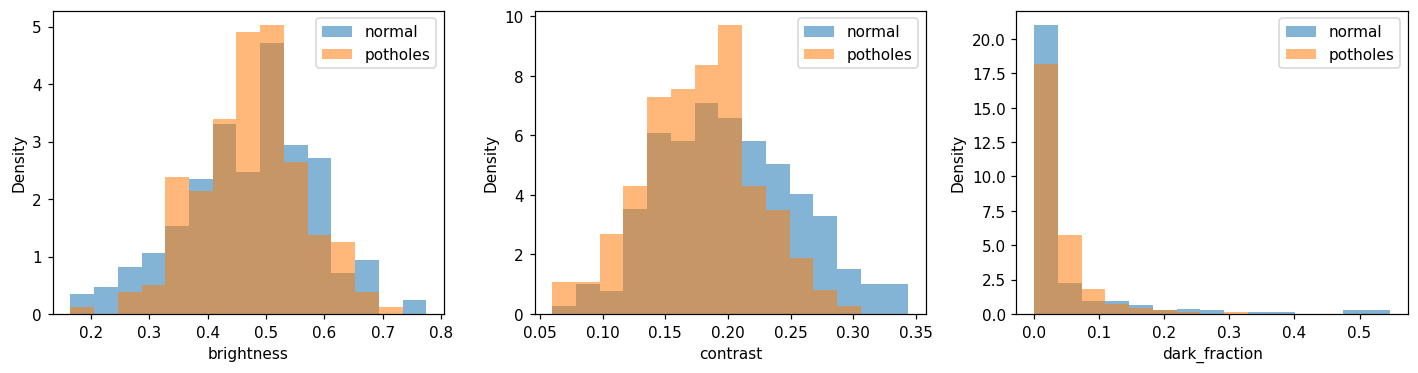

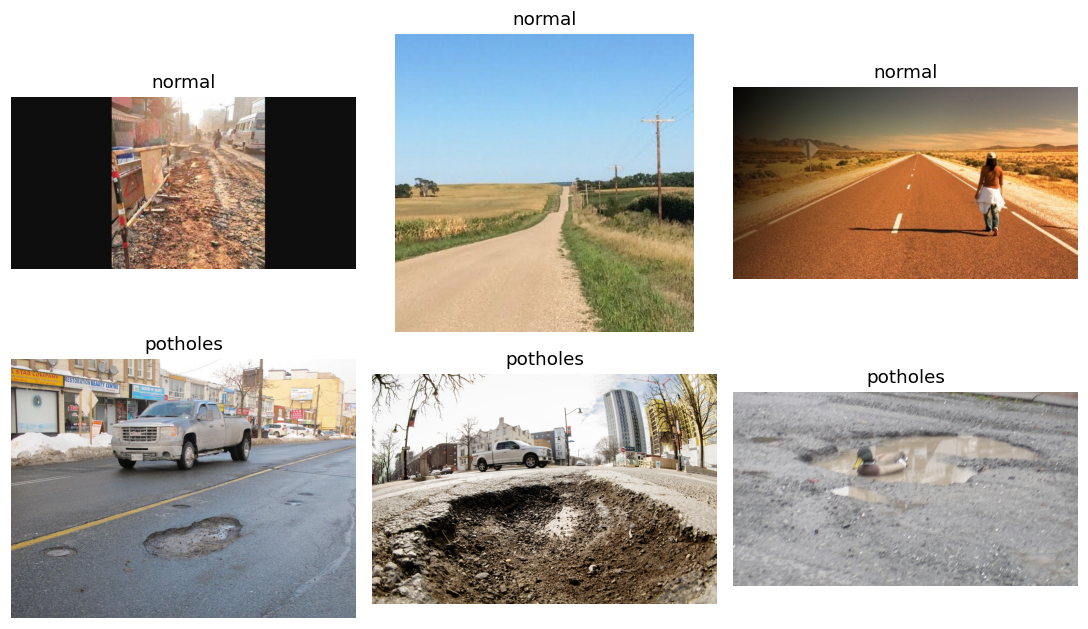

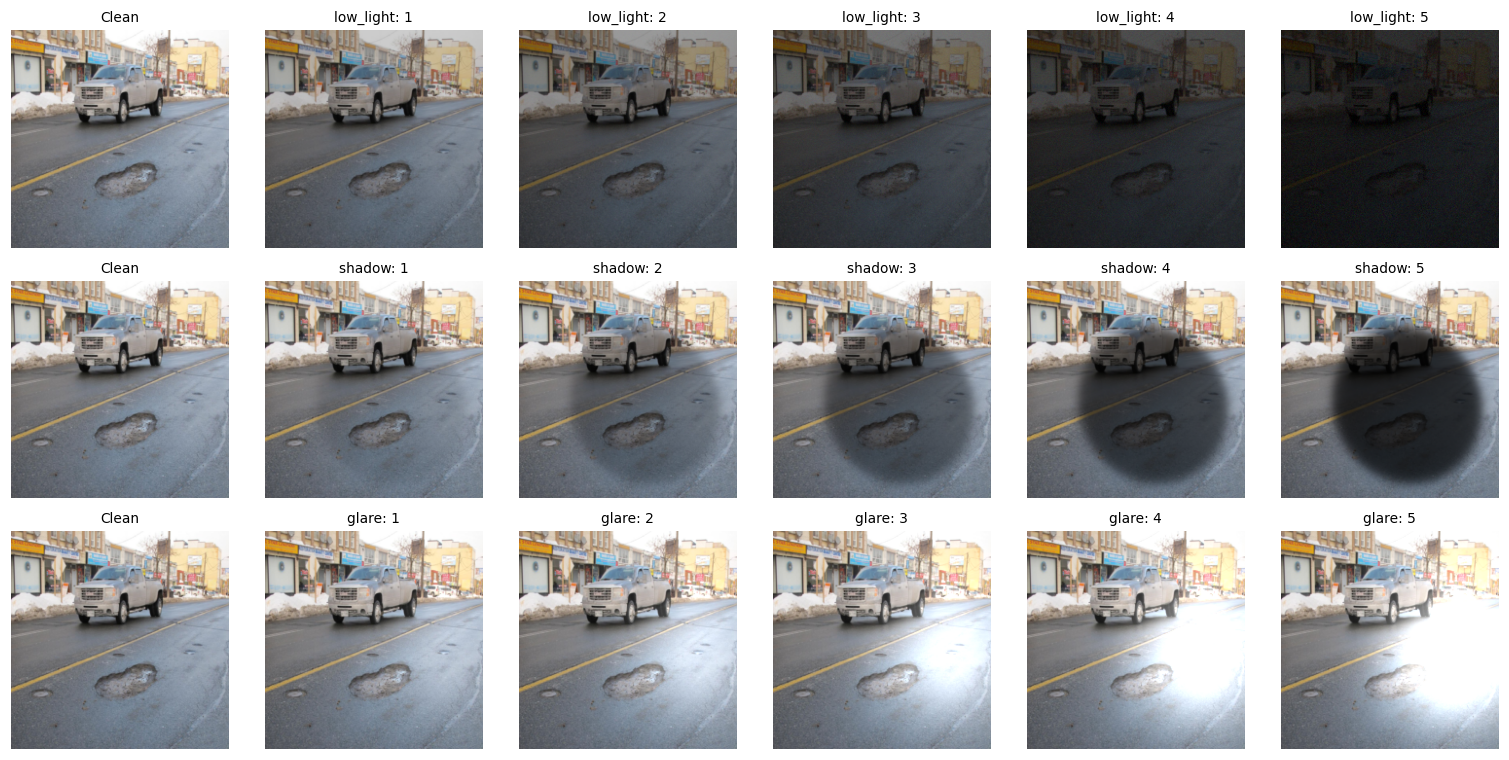

Kondisi evaluasi per gambar: 16

[SMOKE] 3/9 Tuning dan pelatihan


,fold,arch,strategy,seed,best_val,best_epoch
0,0,efficientnet_b0,standard,42,1.000000,2
1,0,efficientnet_b0,jitter,42,0.992643,1
2,0,efficientnet_b0,illum,42,0.992643,2
3,0,mobilenet_v3_large,standard,42,0.970588,2
4,0,mobilenet_v3_large,jitter,42,0.970588,2
5,0,mobilenet_v3_large,illum,42,0.970588,1



[SMOKE] 4/9 Prediksi dan baseline


Baseline test fold 0:   0%|          | 0/16 [00:00<?, ?it/s]

,arch,strategy,seed,kind,severity,replica,condition,accuracy,macro_f1,balanced_accuracy,...,recall_pothole,f1_pothole,n,tn,fp,fn,tp,roc_auc,average_precision,brier
0,efficientnet_b0,illum,42,clean,0,0,clean_s0_r0,0.948148,0.948137,0.948901,...,0.969231,0.947368,135,65,5,2,63,0.997143,0.997069,0.025058
16,efficientnet_b0,jitter,42,clean,0,0,clean_s0_r0,0.955556,0.955553,0.957143,...,1.000000,0.955882,135,64,6,0,65,0.997802,0.997720,0.027602
32,efficientnet_b0,standard,42,clean,0,0,clean_s0_r0,0.962963,0.962955,0.963736,...,0.984615,0.962406,135,66,4,1,64,0.997582,0.997538,0.026288
48,mobilenet_v3_large,illum,42,clean,0,0,clean_s0_r0,0.962963,0.962963,0.964286,...,1.000000,0.962963,135,65,5,0,65,0.997802,0.997786,0.045782
64,mobilenet_v3_large,jitter,42,clean,0,0,clean_s0_r0,0.925926,0.925922,0.927473,...,0.969231,0.926471,135,62,8,2,63,0.994725,0.994758,0.056287
80,mobilenet_v3_large,standard,42,clean,0,0,clean_s0_r0,0.925926,0.925922,0.927473,...,0.969231,0.926471,135,62,8,2,63,0.995385,0.995499,0.055549



[SMOKE] 5/9 Ringkasan kinerja dan kesalahan


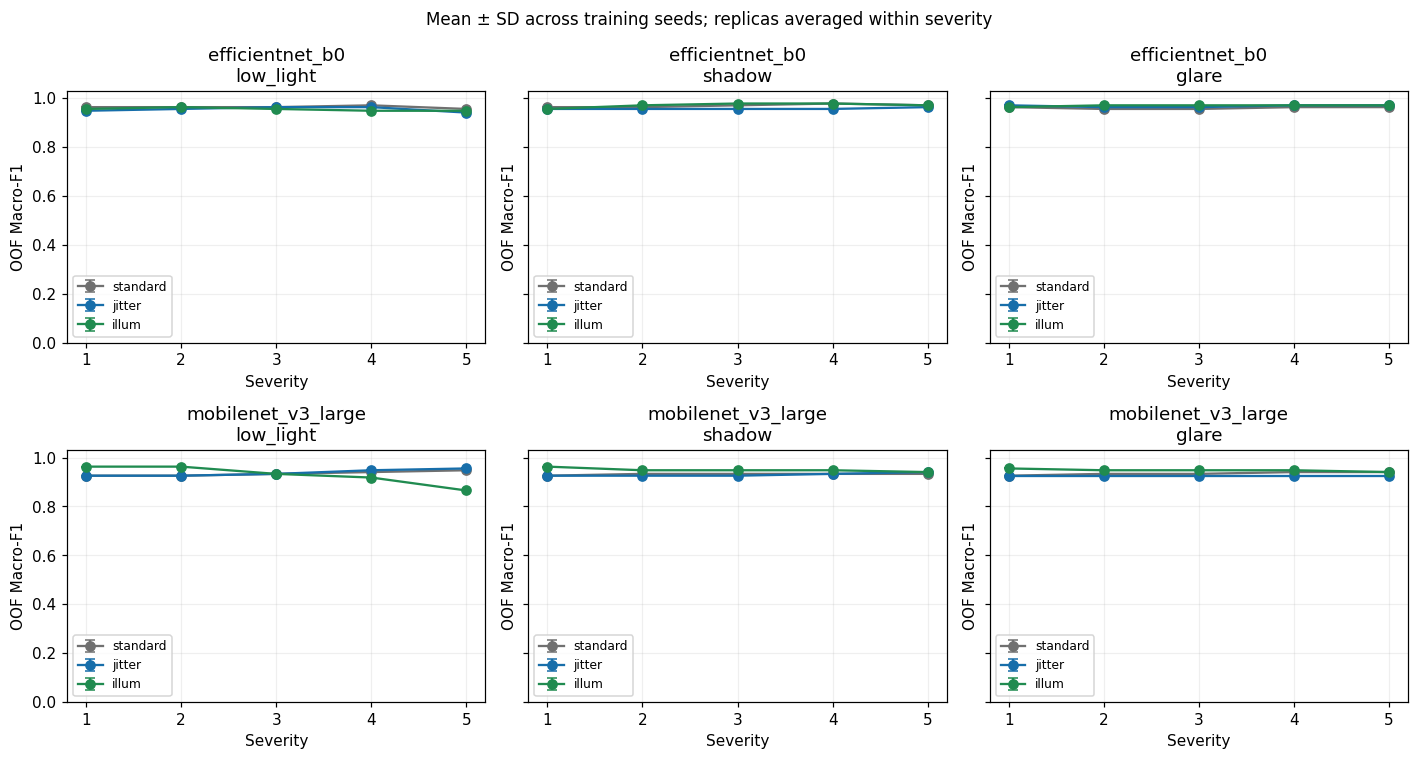

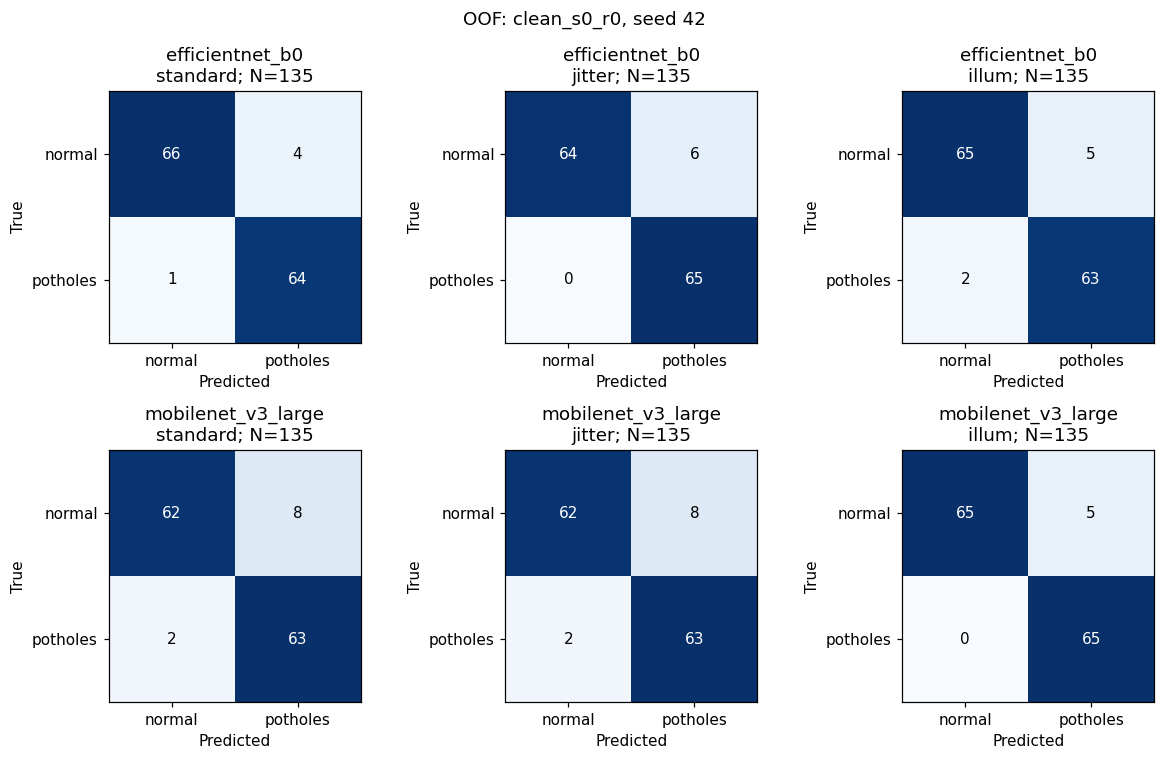

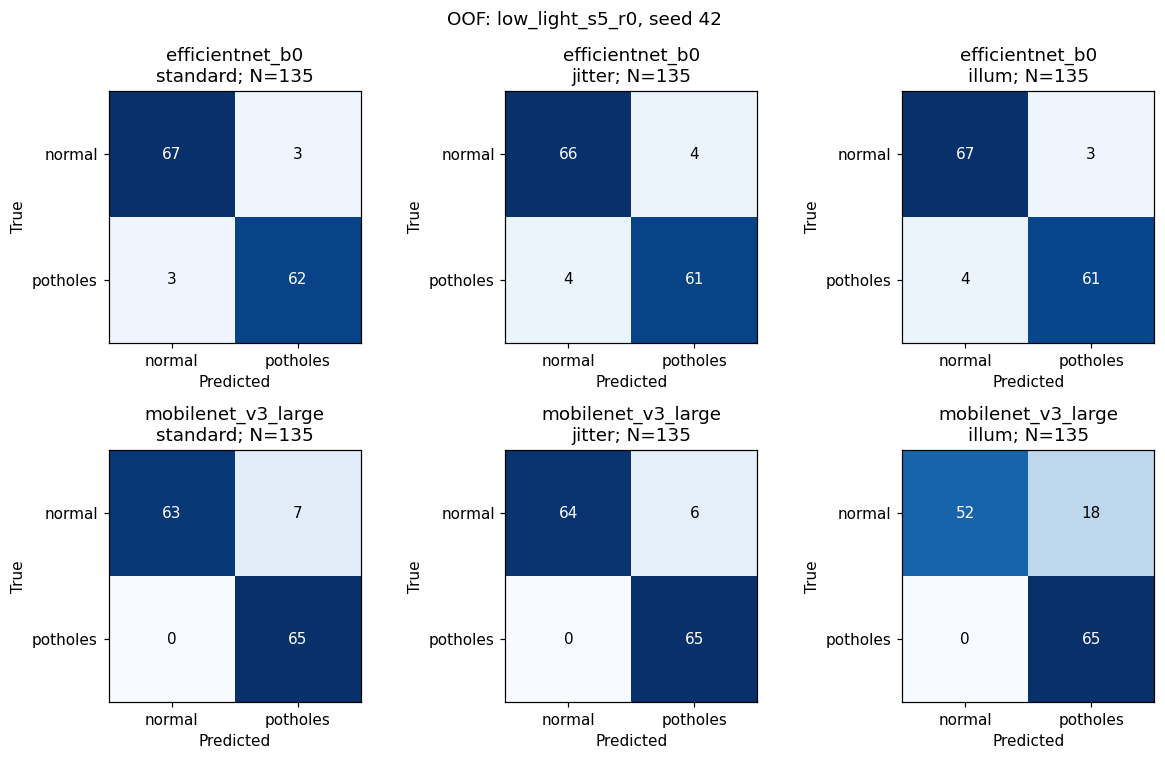

,arch,strategy,scope,macro_f1_mean,macro_f1_std,recall_pothole_mean,recall_pothole_std,recall_normal_mean,recall_normal_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,brier_mean,brier_std
0,efficientnet_b0,illum,clean,0.948137,NaN,0.969231,NaN,0.928571,NaN,0.948148,NaN,0.948901,NaN,0.025058,NaN
1,efficientnet_b0,illum,trained_families_all_severity,0.962205,NaN,0.981538,NaN,0.944286,NaN,0.962222,NaN,0.962912,NaN,0.028163,NaN
2,efficientnet_b0,illum,trained_families_severity_1_3,0.962956,NaN,0.987179,NaN,0.940476,NaN,0.962963,NaN,0.963828,NaN,0.026369,NaN
3,efficientnet_b0,illum,trained_families_severity_4_5,0.961078,NaN,0.973077,NaN,0.950000,NaN,0.961111,NaN,0.961538,NaN,0.030853,NaN
4,efficientnet_b0,illum,untrained_glare_operator,0.968871,NaN,0.981538,NaN,0.957143,NaN,0.968889,NaN,0.969341,NaN,0.023362,NaN
5,efficientnet_b0,jitter,clean,0.955553,NaN,1.000000,NaN,0.914286,NaN,0.955556,NaN,0.957143,NaN,0.027602,NaN
6,efficientnet_b0,jitter,trained_families_all_severity,0.955545,NaN,0.987692,NaN,0.925714,NaN,0.955556,NaN,0.956703,NaN,0.033241,NaN
7,efficientnet_b0,jitter,trained_families_severity_1_3,0.955553,NaN,0.992308,NaN,0.921429,NaN,0.955556,NaN,0.956868,NaN,0.030388,NaN
8,efficientnet_b0,jitter,trained_families_severity_4_5,0.955533,NaN,0.980769,NaN,0.932143,NaN,0.955556,NaN,0.956456,NaN,0.037521,NaN
9,efficientnet_b0,jitter,untrained_glare_operator,0.967404,NaN,0.996923,NaN,0.940000,NaN,0.967407,NaN,0.968462,NaN,0.026921,NaN



[SMOKE] 6/9 Statistik berpasangan


,arch,contrast,scope,delta_percentage_points,ci95_low,ci95_high,ci_adjusted_low,ci_adjusted_high
0,efficientnet_b0,illum - standard,trained_families_all_severity,-0.370745,-0.011210,0.004459,-0.013092,0.006544
1,efficientnet_b0,illum - standard,clean,-1.481807,-0.030321,0.000000,-0.041579,0.000000
2,efficientnet_b0,illum - standard,untrained_glare_operator,0.889410,-0.001493,0.025216,-0.003003,0.034729
3,efficientnet_b0,illum - jitter,trained_families_all_severity,0.666015,-0.003741,0.023037,-0.007063,0.029377
4,efficientnet_b0,illum - jitter,clean,-0.741635,-0.031334,0.014914,-0.044823,0.026595
5,efficientnet_b0,illum - jitter,untrained_glare_operator,0.146684,-0.013407,0.017835,-0.017815,0.022090
6,mobilenet_v3_large,illum - standard,trained_families_all_severity,0.578150,-0.010937,0.026873,-0.017164,0.037102
7,mobilenet_v3_large,illum - standard,clean,3.704110,0.007470,0.074344,0.003070,0.088878
8,mobilenet_v3_large,illum - standard,untrained_glare_operator,1.332748,0.000000,0.032609,-0.002954,0.047311
9,mobilenet_v3_large,illum - jitter,trained_families_all_severity,0.504068,-0.013148,0.020803,-0.017294,0.027306



[SMOKE] 7/9 Grad-CAM


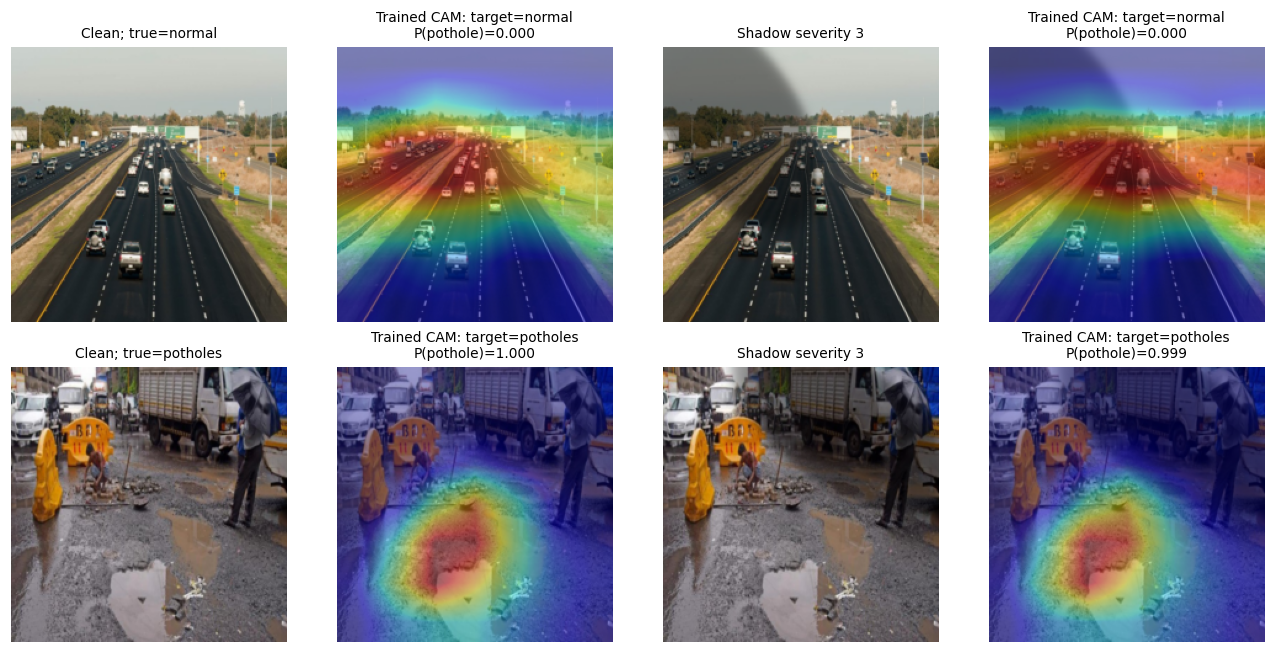

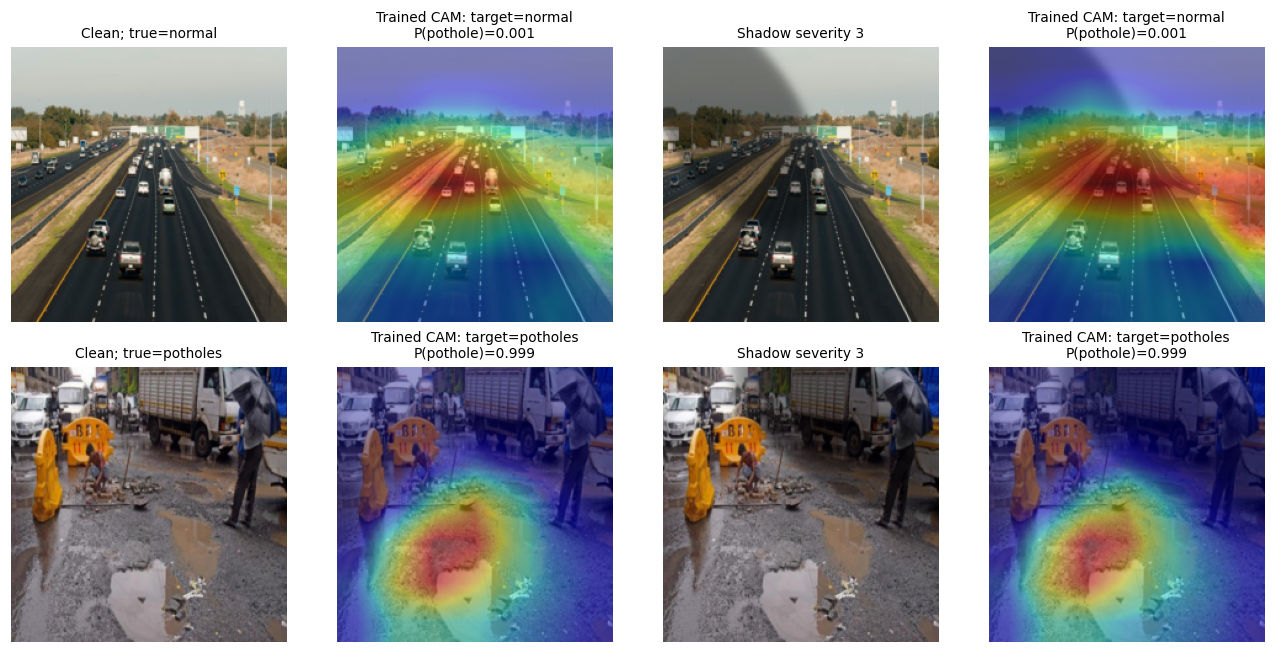

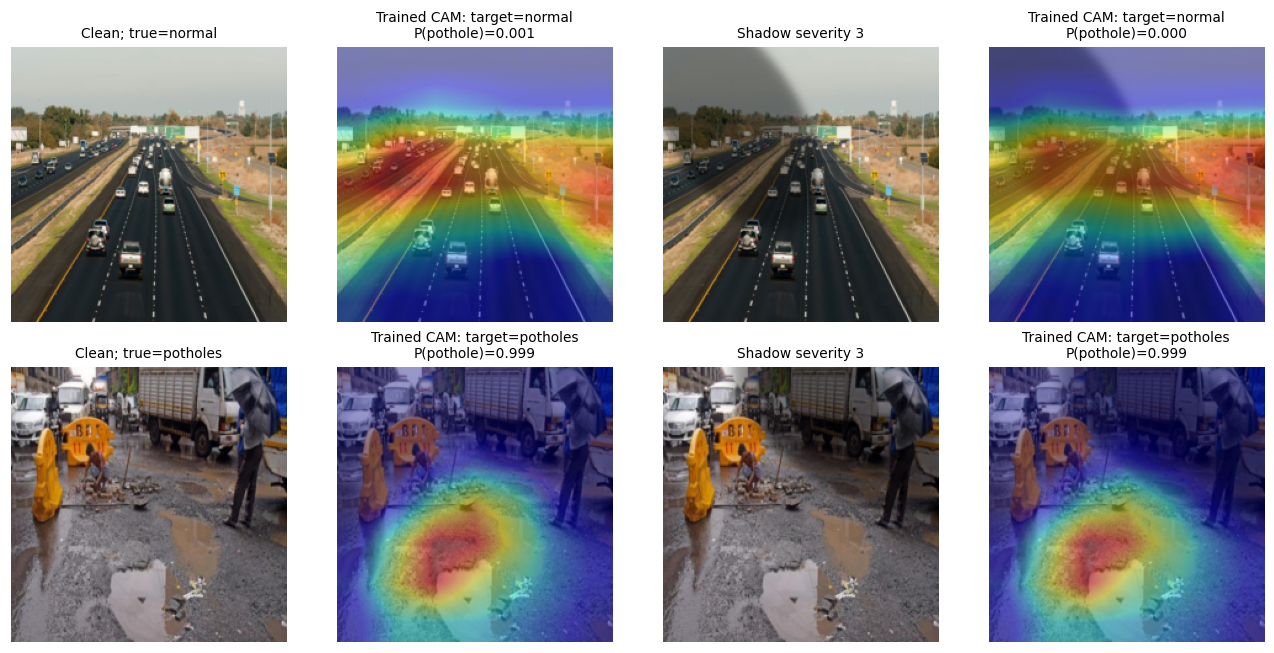

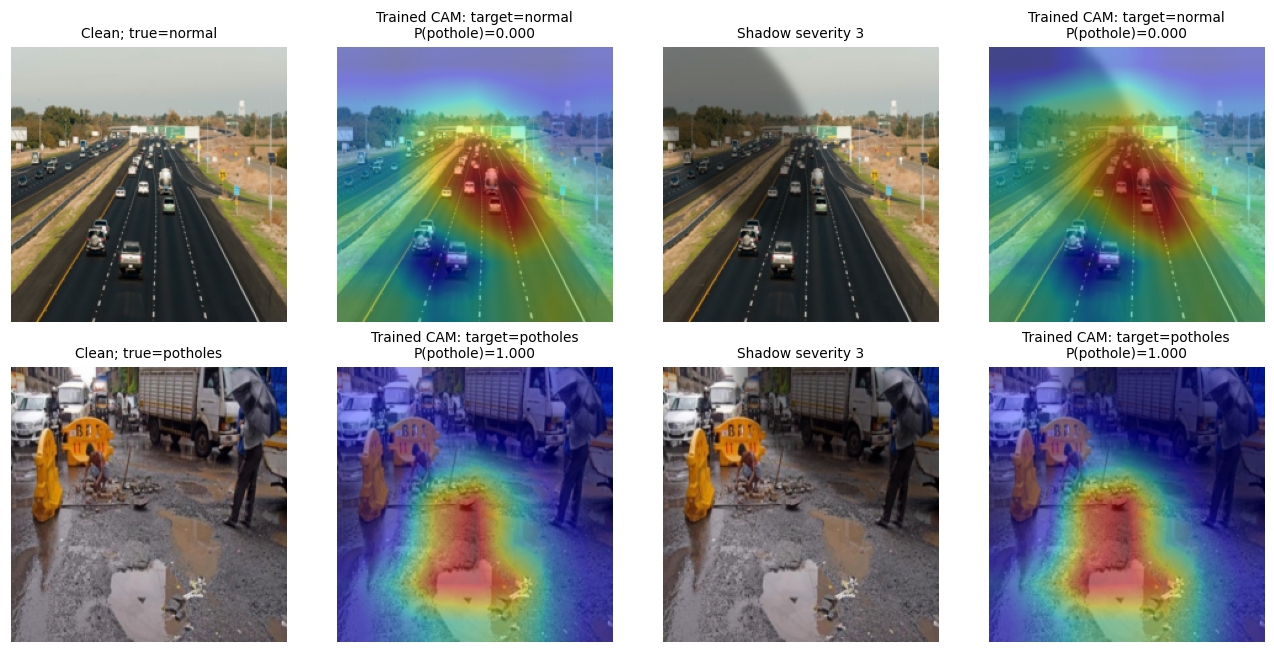

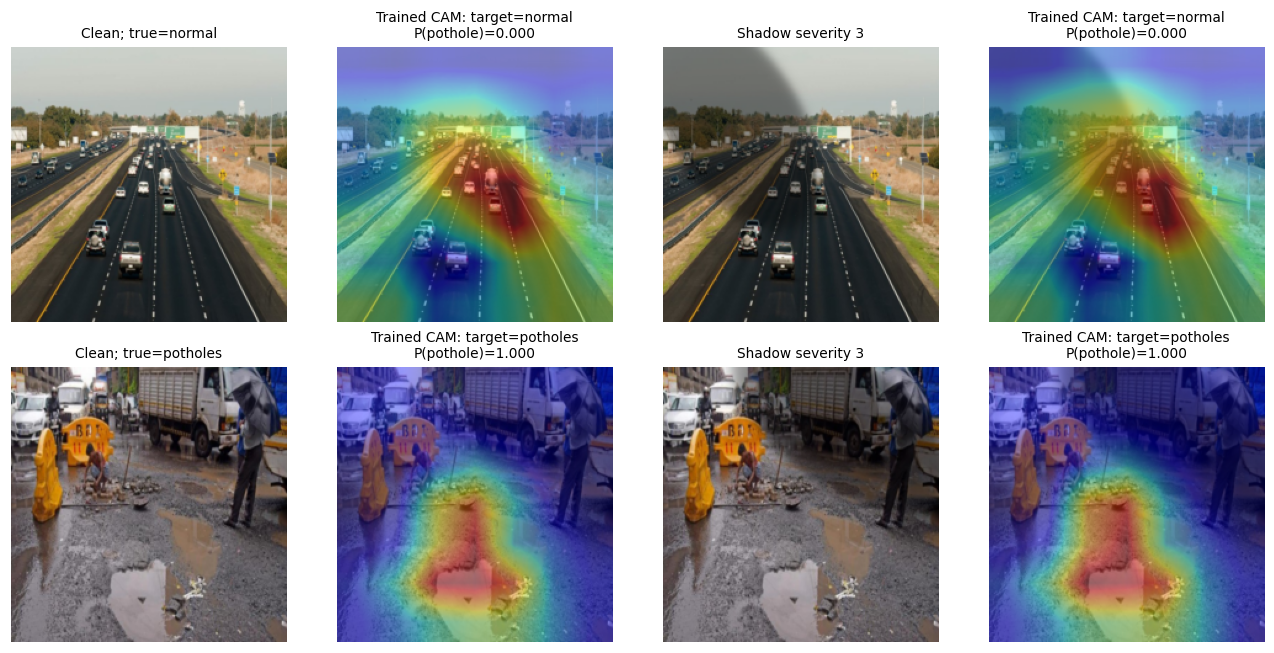

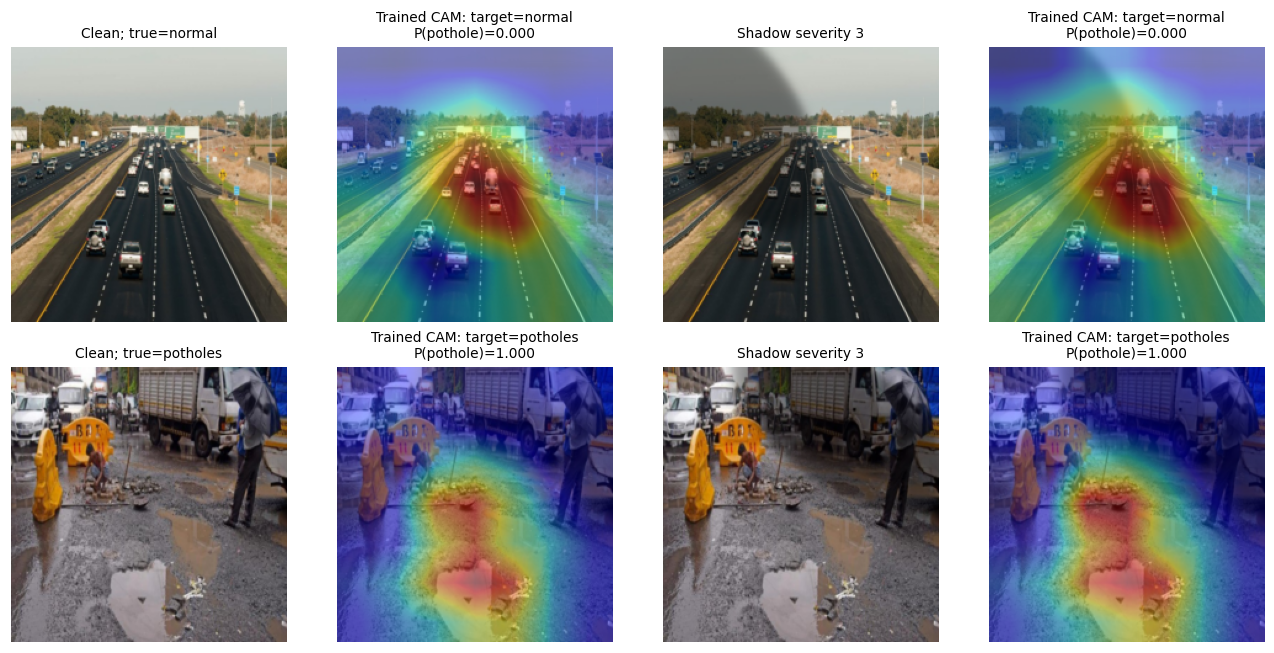

,arch,strategy,comparison,n_comparisons,n_unique_images,n_valid,mean_spearman,median_spearman,trained_zero_count,comparison_zero_count,n_undefined
0,efficientnet_b0,illum,all_parameters_randomized,2,2,0,NaN,NaN,0,2,2
1,efficientnet_b0,illum,clean_vs_shadow_s3,2,2,2,0.987155,0.987155,0,0,0
2,efficientnet_b0,illum,head_randomized,2,2,2,-0.585883,-0.585883,0,0,0
3,efficientnet_b0,jitter,all_parameters_randomized,2,2,0,NaN,NaN,0,2,2
4,efficientnet_b0,jitter,clean_vs_shadow_s3,2,2,2,0.976761,0.976761,0,0,0
5,efficientnet_b0,jitter,head_randomized,2,2,2,-0.589932,-0.589932,0,0,0
6,efficientnet_b0,standard,all_parameters_randomized,2,2,0,NaN,NaN,0,2,2
7,efficientnet_b0,standard,clean_vs_shadow_s3,2,2,2,0.989394,0.989394,0,0,0
8,efficientnet_b0,standard,head_randomized,2,2,2,-0.599458,-0.599458,0,0,0
9,mobilenet_v3_large,illum,all_parameters_randomized,2,2,2,0.204998,0.204998,0,0,0



[SMOKE] 8/9 Benchmark


,arch,parameters,state_dict_MiB,conv_linear_MACs,device,scope,precision,batch_size,cpu_threads_actual,cpu_interop_threads,n_iterations,warmup,p50_ms,p95_ms,mean_ms,inverse_p50_per_second,gpu_peak_allocated_MiB
0,efficientnet_b0,4010110,15.576644,384537312,cpu,model_forward_only,FP32,1,1,6,10,3,38.26150,42.005810,37.69748,26.135933,NaN
1,efficientnet_b0,4010110,15.576644,384537312,cuda,model_forward_only,FP32,1,6,6,10,3,15.56795,21.206910,15.05215,64.234533,90.061523
2,mobilenet_v3_large,4204594,16.230544,215312320,cpu,model_forward_only,FP32,1,1,6,10,3,21.29025,25.365295,20.98117,46.969857,NaN
3,mobilenet_v3_large,4204594,16.230544,215312320,cuda,model_forward_only,FP32,1,6,6,10,3,7.33595,9.023750,7.63196,136.314997,87.674805



[SMOKE] 9/9 Paket hasil


Pipeline selesai. Paket hasil: E:\LPPM\3 JURNAL\Evaluasi Augmentasi Pencahayaan Sintetis terhadap Ketahanan Klasifikasi Lubang Jalan pada EfficientNet-B0 dan MobileNetV3-Large\outputs\protocol_v2_1\smoke\results_protocol_v2_1_smoke.zip
Status: smoke_only
Hasil smoke TIDAK BOLEH dipakai sebagai hasil penelitian.


{'protocol_version': '2.1.0',
 'signature': '445388d1f84897429e011209dc27b93f1938a7bdddc13f6454b449ac72e0cac0',
 'profile': 'smoke',
 'completed_utc': '2026-10-12T05:51:11.168017+00:00',
 'full_five_fold_run': False,
 'n_unique_images': 676,
 'n_unique_tested_images': 135,
 'n_groups': 676,
 'n_main_runs': 6,
 'n_seeds': 1,
 'n_conditions': 16,
 'n_prediction_rows': 12960,
 'numerical_pipeline_complete': True,
 'external_validation_completed': False,
 'dataset_provenance_complete': True,
 'inference_status': 'smoke_only',
 'limitations': ['No verified geographical independence',
  'Synthetic, not field nighttime validation',
  'Conditional bootstrap omits full training uncertainty',
  'Revision designed after v1 was observed',
  'CAM diagnostics do not demonstrate causality']}

In [14]:
smoke_results=run_experiment('smoke')

## 13. Jalankan RESEARCH — eksperimen lengkap
**Jalankan sel ini sesudah smoke selesai. Tidak perlu mengubah PROFILE atau restart kernel.**
Research memuat kembali konfigurasi lengkap: 5 test fold, 3 seed, maksimum
20 epoch utama, 90 main runs + 20 tuning runs, dan 44 kondisi.
Output: `outputs/protocol_v2_1/research/`. Hasil/checkpoint smoke tidak dipakai
untuk pelatihan research. Kirim `results_protocol_v2_1_research.zip` setelah selesai.
Untuk melanjutkan research setelah kernel terputus, jalankan kembali semua
sel persiapan, lewati sel SMOKE, lalu jalankan sel RESEARCH; resume tetap aktif.

Hasil dapat dibuka terpisah, misalnya `smoke_results["performance_summary"]`
atau `research_results["performance_summary"]`.

In [14]:
research_results=run_experiment('research')

Profil: research | perangkat: cuda | output: E:\LPPM\3 JURNAL\Evaluasi Augmentasi Pencahayaan Sintetis terhadap Ketahanan Klasifikasi Lubang Jalan pada EfficientNet-B0 dan MobileNetV3-Large\outputs\protocol_v2_1\research
Main runs: 90 | kondisi: 44

[RESEARCH] 1/9 Audit data dan pembagian fold


class_name,normal,potholes,All
fold,,,
0,70,65,135
1,70,66,136
2,70,65,135
3,70,65,135
4,69,66,135
All,349,327,676


{'raw_readable': 681, 'unreadable': 0, 'unique_images': 676, 'exact_duplicates_removed': 5, 'n_groups': 676, 'max_group_size': 1, 'near_pairs': 0, 'images_with_source_metadata': 0, 'source_independence_verified': False}

[RESEARCH] 2/9 EDA dan gangguan sintetis


C:\Users\aseps\AppData\Local\Temp\ipykernel_10820\2478824013.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show();plt.close(fig)


C:\Users\aseps\AppData\Local\Temp\ipykernel_10820\2478824013.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show();plt.close(fig)


C:\Users\aseps\AppData\Local\Temp\ipykernel_10820\2478824013.py:19: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show();plt.close(fig)


... (1,250 outputs left out)

,arch,parameters,state_dict_MiB,conv_linear_MACs,device,scope,precision,batch_size,cpu_threads_actual,cpu_interop_threads,n_iterations,warmup,p50_ms,p95_ms,mean_ms,inverse_p50_per_second,gpu_peak_allocated_MiB
0,efficientnet_b0,4010110,15.576644,384537312,cpu,model_forward_only,FP32,1,1,6,200,30,38.77085,52.964495,40.139483,25.792574,NaN
1,efficientnet_b0,4010110,15.576644,384537312,cuda,model_forward_only,FP32,1,6,6,200,30,10.53965,19.039105,11.816683,94.879811,90.061523
2,mobilenet_v3_large,4204594,16.230544,215312320,cpu,model_forward_only,FP32,1,1,6,200,30,18.39705,31.829300,20.274990,54.356541,NaN
3,mobilenet_v3_large,4204594,16.230544,215312320,cuda,model_forward_only,FP32,1,6,6,200,30,7.70235,13.245180,8.502781,129.830506,87.674805



[RESEARCH] 9/9 Paket hasil


Pipeline selesai. Paket hasil: E:\LPPM\3 JURNAL\Evaluasi Augmentasi Pencahayaan Sintetis terhadap Ketahanan Klasifikasi Lubang Jalan pada EfficientNet-B0 dan MobileNetV3-Large\outputs\protocol_v2_1\research\results_protocol_v2_1_research.zip
Status: exploratory_internal_validation


{'protocol_version': '2.1.0',
 'signature': 'a1fddfebf5392cea06549c3c1f581e76150a5dc48c5194eca6b78155e746b062',
 'profile': 'research',
 'completed_utc': '2026-10-12T14:14:08.879441+00:00',
 'full_five_fold_run': True,
 'n_unique_images': 676,
 'n_unique_tested_images': 676,
 'n_groups': 676,
 'n_main_runs': 90,
 'n_seeds': 3,
 'n_conditions': 44,
 'n_prediction_rows': 535392,
 'numerical_pipeline_complete': True,
 'external_validation_completed': False,
 'dataset_provenance_complete': True,
 'inference_status': 'exploratory_internal_validation',
 'limitations': ['No verified geographical independence',
  'Synthetic, not field nighttime validation',
  'Conditional bootstrap omits full training uncertainty',
  'Revision designed after v1 was observed',
  'CAM diagnostics do not demonstrate causality']}